# **FGD 6: Analisis Perbedaan Kinerja DenseNet121 dan Lightweight DenseNet (LWDN) pada Klasifikasi Citra Daun Tanaman Obat 🪴🌿**

## **CRISP-DM Phase 1: Business Understanding**
### *1. Tujuan Bisnis*
Proyek ini bertujuan untuk mengembangkan, membandingkan, dan mengevaluasi sistem klasifikasi jenis tanaman herbal berbasis citra daun menggunakan model Lightweight DenseNet (LWDN) sebagai arsitektur yang lebih ringan dengan DenseNet121 sebagai model acuan (baseline), sehingga identifikasi jenis tanaman herbal dapat dilakukan secara otomatis, cepat, dan konsisten. Hasil perbandingan dipakai untuk menentukan model yang paling layak menjadi dasar aplikasi identifikasi tanaman herbal bagi masyarakat, petani, dan pelaku industri obat tradisional.

###*2. Sasaran Bisnis*
* **Meningkatkan efisiensi identifikasi tanaman herbal**: Mengotomatisasi pengenalan jenis tanaman herbal dari citra daun sehingga mengurangi ketergantungan pada identifikasi manual oleh ahli botani atau tenaga berpengalaman.
* **Mengurangi risiko salah identifikasi:** salah mengenali tanaman herbal dapat memengaruhi kualitas dan keamanan penggunaannya.
* **Mendukung edukasi dan pelestarian pengetahuan tanaman obat**: Menjadi alat bantu belajar bagi masyarakat, pelajar, dan peneliti untuk mengenali berbagai jenis tanaman herbal.
* **Menjamin kualitas data:** dataset diperiksa terhadap duplikat, salah label, dan anomali citra (autoencoder) agar evaluasi model dapat dipercaya.
* **Menyediakan model yang layak untuk perangkat terbatas:** LWDN diharapkan lebih kecil dan cepat tanpa penurunan akurasi yang berarti, sehingga cocok untuk aplikasi web/mobile.

###*3. Kendala Bisnis*
* **Keterbatasan data** : Hanya 10 spesies/kelas dengan 350 citra per kelas, dari satu sumber dataset. Citra berupa daun tunggal berlatar putih, sehingga belum mewakili foto lapangan (latar alami, banyak daun, pencahayaan beragam). Hanya organ daun, tidak termasuk batang, bunga, atau buah
* **Sebaran kelas:** awalnya seimbang. Setelah cleansing jumlah per kelas bisa sedikit berbeda, sehingga dipakai *stratified split* dan augmentasi pada semua kelas untuk menyamakan jumlah data latih.
### *4. Kriteria Keberhasilan (Success Criteria)*



**Install & Import Library**

In [ ]:
# initial Setup & Utilities
!pip -q install gdown opencv-python-headless tensorflow

import os, sys, random, hashlib, zipfile, shutil, json, warnings
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import cv2
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf


# **Penjelasan :**
*   import os, sys, random, hashlib, zipfile, shutil, json, warnings → untuk akses file/folder/ukuran file, akses informasi dan fungsi, proses sampling, deteksi gambar duplikat, membaca/menulis data berformat.
*   from pathlib import Path → Mengelola lokasi file.
*   from collections import Counter → Menghitung frekuensi &format gambar
*   import ThreadPoolExecutor → Menjalankan beberapa pekerjaan file secara paralel agar pemeriksaan banyak gambar lebih cepat.
*   import pandas → Membuat tabel master dataset, membersihkan data, dan menghitung distribusi kelas.
*   import seaborn → Membuat grafik statistik, seperti
diagram batang dan boxplot, dengan lebih praktis.
*   import matplotlib.pyplot → Menampilkan gambar, grafik, dan visualisasi hasil pengolahan data.
*   import cv2 → Membaca citra, mengubah ruang warna, dan menghitung karakteristik kualitas gambar.
*   from PIL import Image, ImageOps → Membaca, mengubah ukuran, mengonversi, dan menyimpan gambar.
*   import train_test_split → Membagi dataset menjadi train, validation, dan test
*   import compute_class_weight → Menghitung bobot kelas untuk membantu penanganan ketidakseimbangan kelas saat pelatihan.
*   import tensorflow → pemrosesan dataset, augmentasi, dan komponen deep learning.







In [ ]:
# initial Setup & Utilities
gpus = tf.config.list_physical_devices("GPU") # mengetahui apakah GPU tersedia
print("TensorFlow:", tf.__version__)  # mengetahui versi TensorFlow yang aktif
print("GPU       :", [g.name for g in gpus] if gpus else "tidak ada (berjalan di CPU)")

sns.set_theme(style="whitegrid")  # tema grafik

# membuat proses pengacakan data lebih konsisten dengan seed.
SEED = 42
random.seed(SEED);
np.random.seed(SEED);
tf.random.set_seed(SEED)

#Konfigurasi
FILE_ID       = "1jieheQOYqDga1FhBKQgs6tcwVX02uWQr"  #identitas dataset di Google Drive.
EXPECTED_SIZE = 393505457

WORK_DIR = Path("/content/work")
ZIP_PATH = str(WORK_DIR / "dataset.zip")
RAW_DIR  = WORK_DIR / "raw"
PREP_DIR = WORK_DIR / "dataset_224"
IMG_SIZE = 224 # ukuran citra yang digunakan sebagai masukan model(224 karna umum untuk CNN berbasis imagenet)
BATCH    = 32 # jumlah gambar yang diproses dalam satu batch.
SPLIT    = (0.80, 0.10, 0.10) # proporsi pembagian data menjadi 80% train, 10% validation, dan 10% test.
IMG_EXT  = {".jpg", ".jpeg", ".png"}
WORK_DIR.mkdir(parents=True, exist_ok=True)

def letterbox(path, size=IMG_SIZE):
    im = Image.open(path)
    im.draft("RGB", (size * 2, size * 2))
    im = ImageOps.exif_transpose(im).convert("RGB")
    im.thumbnail((size, size), Image.LANCZOS)
    canvas = Image.new("RGB", (size, size), (255, 255, 255))
    canvas.paste(im, ((size - im.width) // 2, (size - im.height) // 2))
    return canvas

TensorFlow: 2.21.0
GPU       : tidak ada (berjalan di CPU)


In [ ]:
# initial Setup & Utilities
import gdown # mengambil dataset dari Google Drive, diekstrak, lalu mendata semua gambar ke tabel `df`

# mengunduh dataset jika file belum tersedia atau ukurannya tidak sesuai.
if not (os.path.exists(ZIP_PATH) and os.path.getsize(ZIP_PATH) == EXPECTED_SIZE):
    gdown.download(id=FILE_ID, output=ZIP_PATH, quiet=False)

# ZIP diperiksa ukurannya dan diekstrak ke RAW_DIR
size = os.path.getsize(ZIP_PATH) # Verifikasi unduhan
print(f"Ukuran file: {size:,} | harapan: {EXPECTED_SIZE:,}")
assert size == EXPECTED_SIZE, "Ukuran tidak cocok. Pastikan zip di Drive 'Anyone with the link'."

if not RAW_DIR.exists(): # Ekstrak zip ke disk lokal
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(RAW_DIR)

# Cari folder induk = folder yang punya subfolder kelas terbanyak
cand = [p for p in RAW_DIR.rglob("*") if p.is_dir() and not p.name.startswith("__")]
DATA_ROOT = max(cand, key=lambda d: sum(c.is_dir() for c in d.iterdir()))
print("DATA_ROOT:", DATA_ROOT)

# Bangun tabel inventaris: satu baris per gambar (path, kelas, nama file, ukuran file)
rows = []
for cls_dir in sorted(p for p in DATA_ROOT.iterdir() if p.is_dir()):
    for f in sorted(cls_dir.iterdir()):
        if f.suffix.lower() in IMG_EXT:
            rows.append((str(f), cls_dir.name, f.name, f.stat().st_size))

df = pd.DataFrame(rows, columns=["path", "label", "filename", "file_size"])
CLASS_NAMES = sorted(df["label"].unique())  # daftar kelas, urut abjad (menentukan urutan label one-hot)
print("DATA_ROOT   :", DATA_ROOT)
print(f"Total citra : {len(df)} | Kelas: {len(CLASS_NAMES)} -> {CLASS_NAMES}")

Downloading...
From (original): https://drive.google.com/uc?id=1jieheQOYqDga1FhBKQgs6tcwVX02uWQr
From (redirected): https://drive.google.com/uc?id=1jieheQOYqDga1FhBKQgs6tcwVX02uWQr&confirm=t&uuid=ff608371-b678-4d59-a0d8-20bb311c87c8
To: /content/work/dataset.zip
100%|██████████| 394M/394M [00:06<00:00, 60.4MB/s]


Ukuran file: 393,505,457 | harapan: 393,505,457
DATA_ROOT: /content/work/raw/Indonesian Herb Leaf Dataset 3500
DATA_ROOT   : /content/work/raw/Indonesian Herb Leaf Dataset 3500
Total citra : 3500 | Kelas: 10 -> ['Belimbing Wuluh', 'Jambu Biji', 'Jeruk Nipis', 'Kemangi', 'Lidah Buaya', 'Nangka', 'Pandan', 'Pepaya', 'Seledri', 'Sirih']


## **CRISP-DM Phase 2: DATA UNDERSTANDING**

**Menghitung Jumlah Gambar di Setiap Tiap Kelas**

In [ ]:
counts = df["label"].value_counts().reindex(CLASS_NAMES)
display(counts.to_frame("jumlah_citra").T)

label,Belimbing Wuluh,Jambu Biji,Jeruk Nipis,Kemangi,Lidah Buaya,Nangka,Pandan,Pepaya,Seledri,Sirih
jumlah_citra,350,350,350,350,350,350,350,350,350,350


**Menampilkan Secara Statistik (Diagram Batang)**

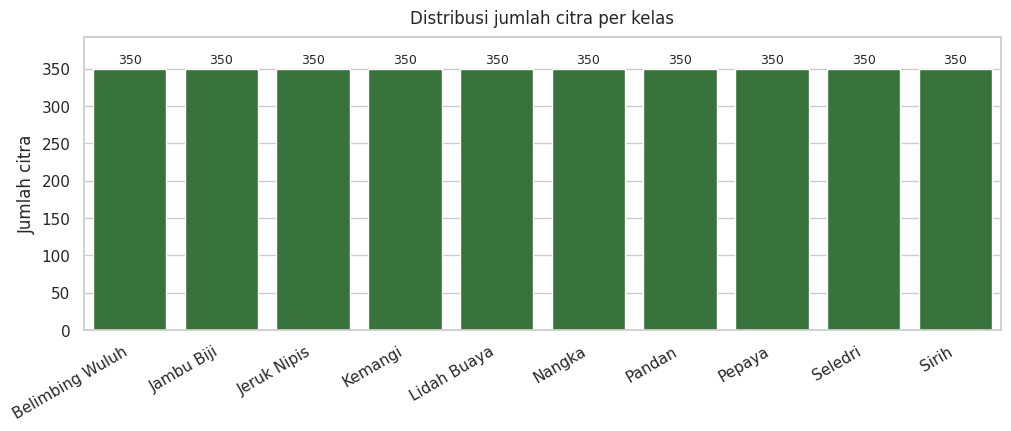

Rasio kelas terbanyak/tersedikit = 1.00 -> seimbang


In [ ]:
# Grafik batang jumlah citra per kelas
fig, ax = plt.subplots(figsize=(10, 4.2), layout="constrained")
sns.barplot(x=counts.index, y=counts.values, ax=ax, color="#2E7D32")
for i, v in enumerate(counts.values):
    ax.text(i, v + counts.max() * 0.01, str(v), ha="center", va="bottom", fontsize=9)   # angka di atas batang
ax.set_ylim(0, counts.max() * 1.12)
ax.set_title("Distribusi jumlah citra per kelas", fontsize=12, pad=10)
ax.set_xlabel(""); ax.set_ylabel("Jumlah citra")
ax.tick_params(axis="x", rotation=30)
plt.setp(ax.get_xticklabels(), ha="right")
plt.show()

# Rasio kelas Mendekati 1 = seimbang
ratio = counts.max() / counts.min()
print(f"Rasio kelas terbanyak/tersedikit = {ratio:.2f} ->", "seimbang" if ratio < 1.5 else "tidak seimbang")

**Menampilkan Secara Visual**

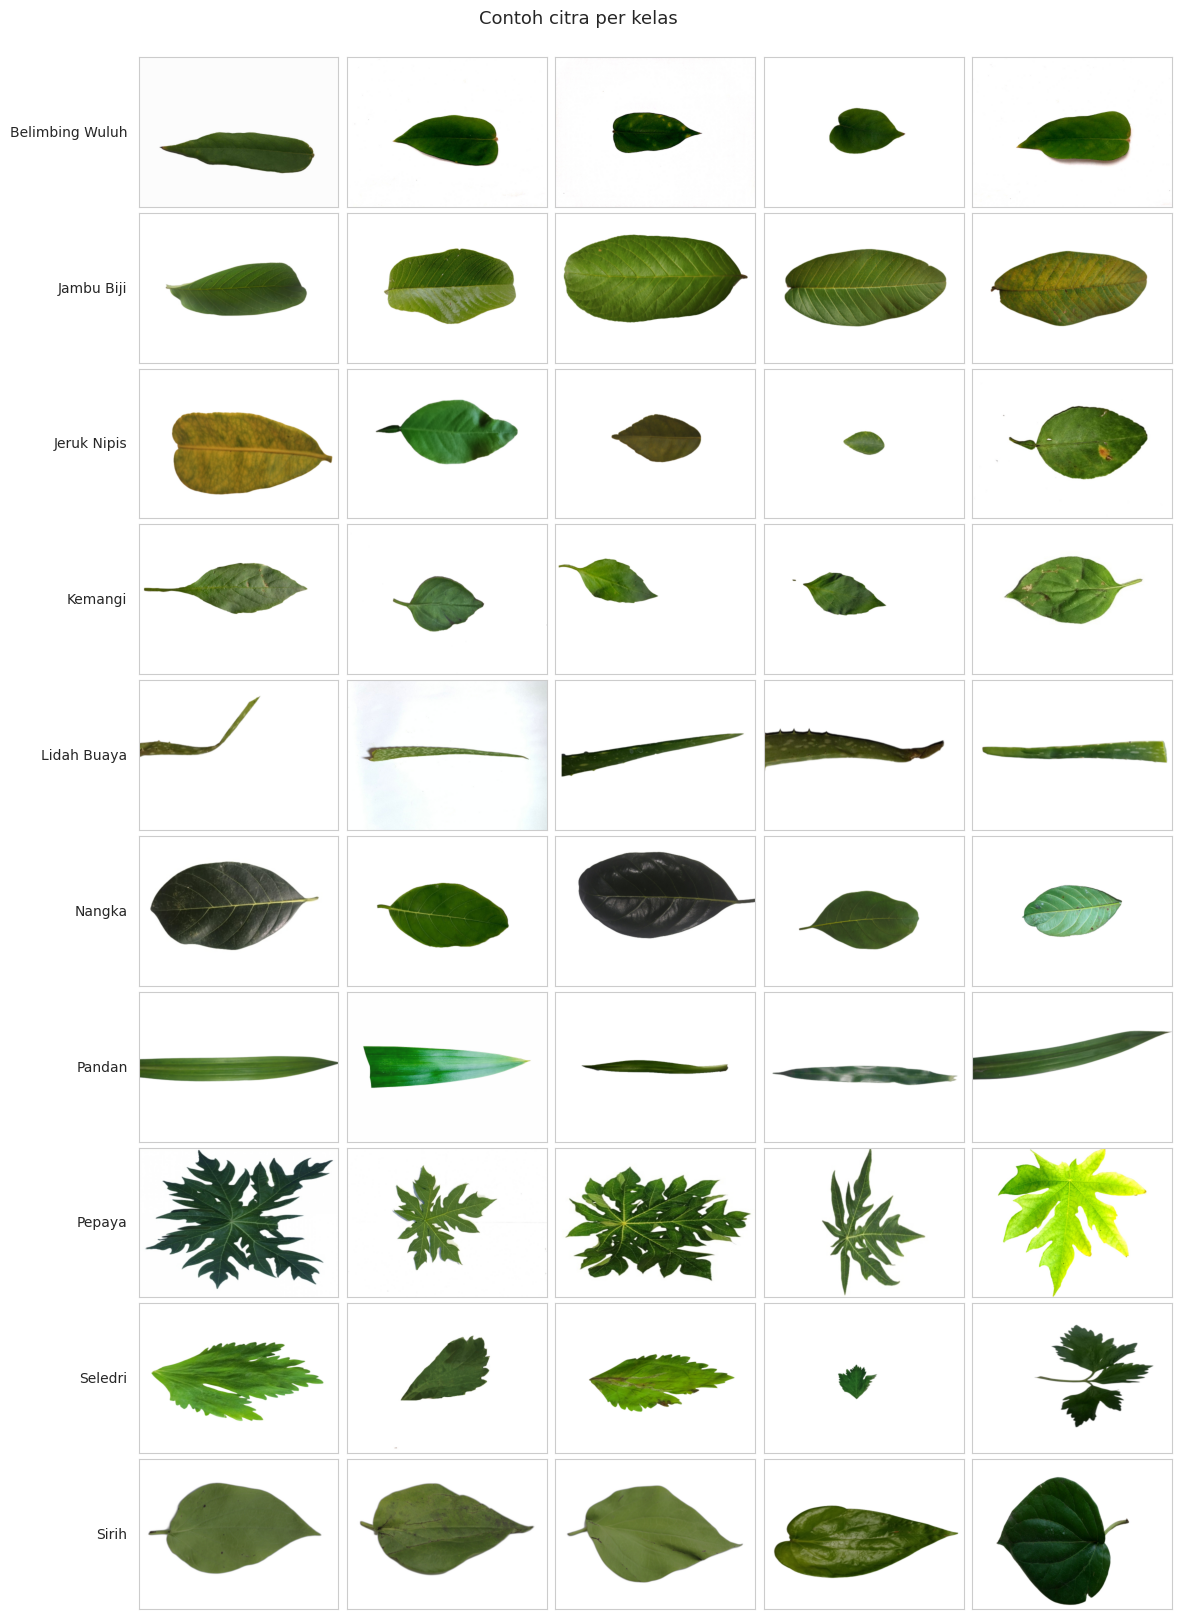

In [ ]:
# Melihat 5 sample citra antar kelas
N_PER_CLASS = 5
n_cls = len(CLASS_NAMES)
cell_w, cell_h = 2.0, 1.5          # ukuran tiap gambar dalam inci (rasio 4:3, sama dengan citra asli)
gap, left_in, top_in = 0.04, 1.6, 0.6   # jarak antar gambar, ruang nama kelas di kiri, ruang judul di atas
W = left_in + N_PER_CLASS * cell_w * (1 + gap)
H = top_in + n_cls * cell_h * (1 + gap)

fig, axes = plt.subplots(
    n_cls, N_PER_CLASS, figsize=(W, H),
    gridspec_kw=dict(wspace=gap, hspace=gap, left=left_in / W, right=0.995, top=1 - top_in / H, bottom=0.005))
fig.suptitle("Contoh citra per kelas", fontsize=13, y=1 - 0.12 / H, va="top")

rng = np.random.default_rng(SEED)
for r, cls in enumerate(CLASS_NAMES):
    paths = rng.choice(df.loc[df.label == cls, "path"].values, N_PER_CLASS, replace=False)
    for c, p in enumerate(paths):
        im = Image.open(p); im.draft("RGB", (400, 300))     # baca versi kecil agar cepat
        ax = axes[r, c]
        ax.imshow(ImageOps.exif_transpose(im))
        ax.set_xticks([]); ax.set_yticks([])                # tanpa angka sumbu
        for sp in ax.spines.values():                       # bingkai tipis abu-abu agar tiap gambar terpisah jelas
            sp.set_edgecolor("#CCCCCC"); sp.set_linewidth(0.8)
        if c == 0:                                          # nama kelas di sisi kiri baris, rata kanan
            ax.set_ylabel(cls, rotation=0, ha="right", va="center", fontsize=10, labelpad=8)
plt.show()

In [ ]:
# memeriksa spesifikasi teknis dan kualitas visual
def read_meta(p):

    try:
        with Image.open(p) as im:
            im.verify() # cek file tidak korup
        with Image.open(p) as im:
            exif = im.getexif()
            return im.width, im.height, im.mode, im.format, int(exif.get(274, 1)), True
    except Exception:
        return None, None, None, None, None, False # gagal dibaca = dianggap rusak

with ThreadPoolExecutor(10) as ex:
    meta = list(ex.map(read_meta, df["path"]))
meta_df = pd.DataFrame(meta, columns=["width", "height", "mode", "format", "exif_orient", "valid"], index=df.index)
for col in meta_df.columns:
    df[col] = meta_df[col]
df["valid"] = df["valid"].astype(bool)

print("Citra korup/tidak terbaca :", int((~df["valid"]).sum()))
print("Format                    :", dict(Counter(df["format"])))
print("Mode warna                :", dict(Counter(df["mode"])))
print("Resolusi (w x h)          :", dict(Counter(zip(df["width"], df["height"])).most_common(5)))
print("Orientasi EXIF != 1       :", int((df["exif_orient"].fillna(1) != 1).sum()), "citra")
print(f"Ukuran file               : rata-rata {df['file_size'].mean()/1024:.0f} KB | "
      f"min {df['file_size'].min()/1024:.0f} KB | maks {df['file_size'].max()/1024:.0f} KB")

def quality_stats(p):

    # Menghitung 3 ukuran kualitas untuk satu gambar
    im = Image.open(p); im.draft("RGB", (400, 300))
    a = np.asarray(ImageOps.exif_transpose(im).convert("RGB"))
    gray = cv2.cvtColor(a, cv2.COLOR_RGB2GRAY)
    return (gray.mean(),
            cv2.Laplacian(gray, cv2.CV_64F).var(),
            (gray < 235).mean())

# Analisis kualitas citra
n_s = min(60, int(df[df.valid]["label"].value_counts().min()))
sample = df[df.valid].groupby("label").sample(n=n_s, random_state=SEED).copy()
with ThreadPoolExecutor(8) as ex:
    q = list(ex.map(quality_stats, sample["path"]))
sample[["brightness", "sharpness", "leaf_ratio"]] = pd.DataFrame(q, index=sample.index)

Citra korup/tidak terbaca : 0
Format                    : {'JPEG': 3500}
Mode warna                : {'RGB': 3500}
Resolusi (w x h)          : {(1600, 1200): 3500}
Orientasi EXIF != 1       : 0 citra
Ukuran file               : rata-rata 132 KB | min 36 KB | maks 524 KB


**Boxplot**

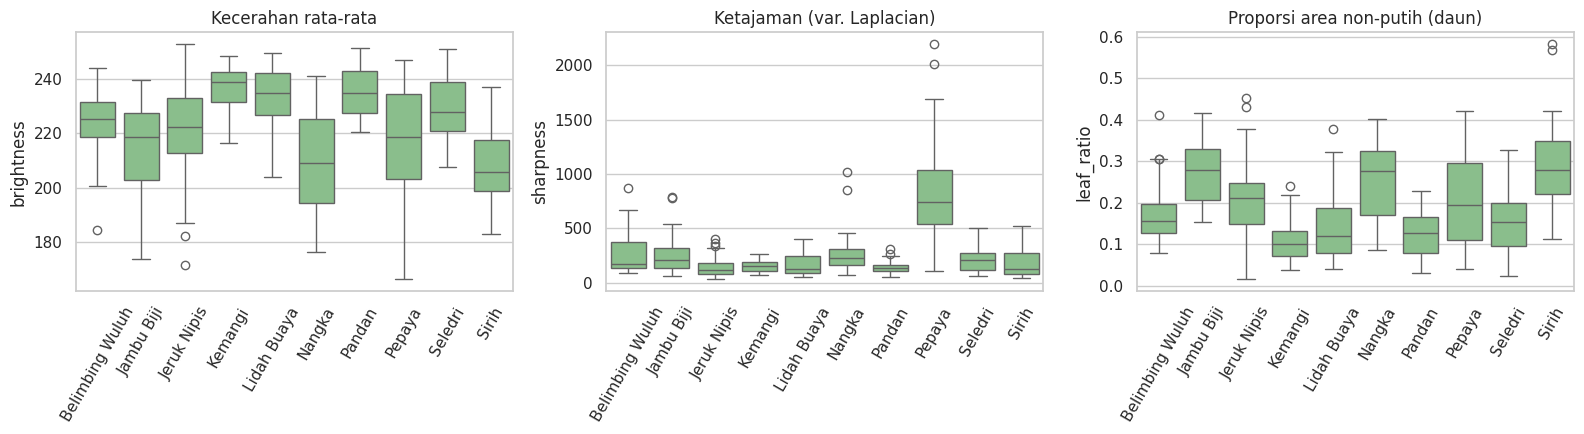

,brightness,sharpness,leaf_ratio
label,,,
Belimbing Wuluh,223.71,261.82,0.17
Jambu Biji,215.27,250.21,0.27
Jeruk Nipis,222.92,138.82,0.20
Kemangi,237.02,153.22,0.11
Lidah Buaya,233.81,167.47,0.14
Nangka,209.51,255.89,0.25
Pandan,234.93,142.86,0.12
Pepaya,217.36,789.02,0.21
Seledri,229.76,215.69,0.15


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, ttl in zip(axes, ["brightness", "sharpness", "leaf_ratio"],
                        ["Kecerahan rata-rata", "Ketajaman (var. Laplacian)", "Proporsi area non-putih (daun)"]):
    sns.boxplot(data=sample, x="label", y=col, ax=ax, color="#81C784")
    ax.set_title(ttl); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()
display(sample.groupby("label")[["brightness", "sharpness", "leaf_ratio"]].mean().round(2))

## **CRISP-DM Phase 3: DATA PREPARATION**


**Data Cleansing**


,jumlah,status
Label kosong,0,aman
File tidak ditemukan / path kosong,0,aman
File 0 byte,0,aman
File sangat kecil (< 5 KB),0,aman
Metadata gagal dibaca (NaN),0,aman
Mode warna bukan RGB,0,aman
File non-gambar di folder kelas,0,aman
Folder kelas kosong,0,aman


Setelah missing/corrupt/duplikat: 3422 citra
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Akurasi prediksi cross-val : 0.9883
Kandidat salah label       : 8 dari 3422


,kandidat
label,
Jambu Biji,1
Jeruk Nipis,2
Lidah Buaya,2
Nangka,1
Pepaya,1
Seledri,1


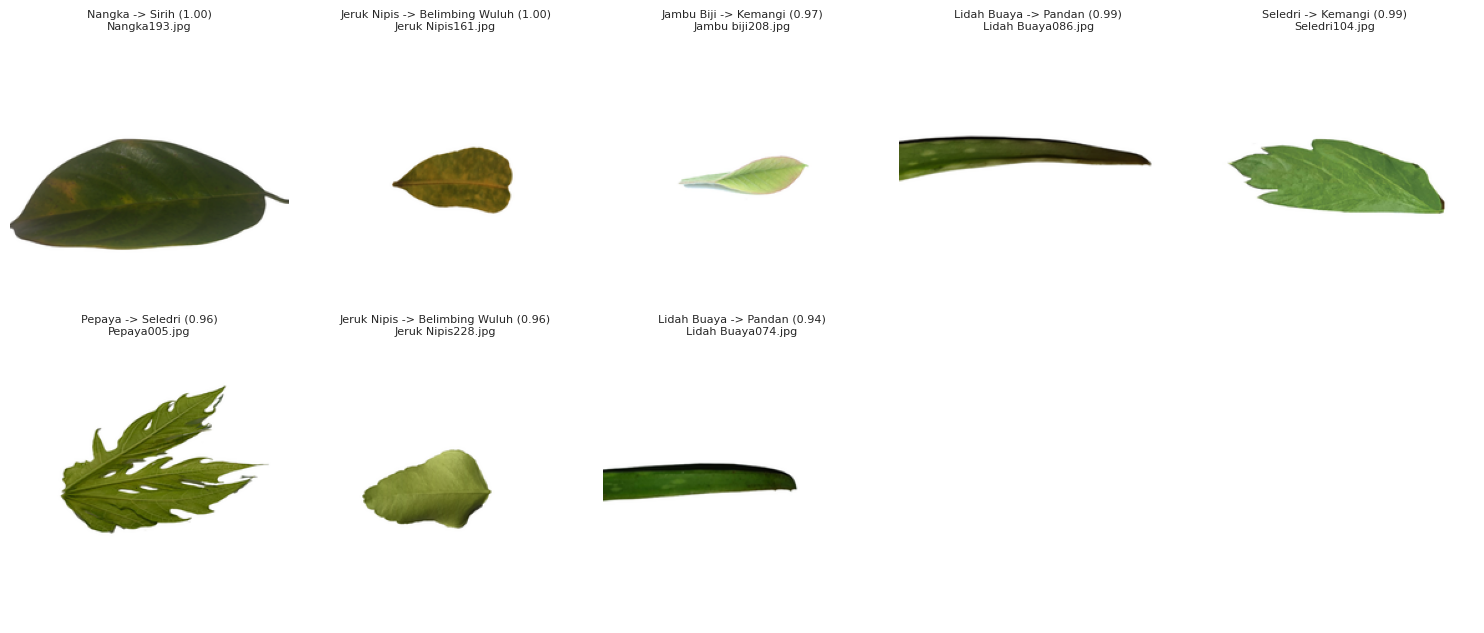

,key,pred_label,p_pred,p_own
1912,Nangka/Nangka193.jpg,Sirih,1.000,0.000
856,Jeruk Nipis/Jeruk Nipis161.jpg,Belimbing Wuluh,0.999,0.001
553,Jambu Biji/Jambu biji208.jpg,Kemangi,0.966,0.005
1457,Lidah Buaya/Lidah Buaya086.jpg,Pandan,0.992,0.008
2834,Seledri/Seledri104.jpg,Kemangi,0.989,0.011
2420,Pepaya/Pepaya005.jpg,Seledri,0.964,0.036
923,Jeruk Nipis/Jeruk Nipis228.jpg,Belimbing Wuluh,0.957,0.043
1445,Lidah Buaya/Lidah Buaya074.jpg,Pandan,0.937,0.063


,tahap,jumlah
0,Data awal,3500
1,1A. Missing value dibuang,0
2,1B. Rusak/corrupt dibuang,0
3,1C. Duplikat konflik dibuang,0
4,1C. Duplikat biasa dibuang,78
5,1D. Salah label dibuang (otomatis),0
6,"1D. Salah label dibuang (manual, DROP_FILES)",0
7,DATA SETELAH CLEANSING,3422


label,Belimbing Wuluh,Jambu Biji,Jeruk Nipis,Kemangi,Lidah Buaya,Nangka,Pandan,Pepaya,Seledri,Sirih
jumlah_setelah_cleansing,349,347,326,350,350,345,349,316,349,341


In [ ]:
from tensorflow.keras.applications import densenet
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Konfigurasi
HAPUS_SALAH_LABEL = False   # False = tinjau manual dulu (isi DROP_FILES); True = hapus otomatis
MAKS_PERSEN = 0.03          # batas aman penghapusan otomatis
THR_OWN = 0.10              # probabilitas kelas aslinya < ambang ini ...
THR_OTHER = 0.90            # ... dan probabilitas kelas lain > ambang ini = kandidat salah label
MIN_CV_ACC = 0.95           # akurasi cross-val minimum agar detektor dianggap andal
KEEP_FILES = []             # "Kelas/nama_file.jpg" yang dipertahankan walau ditandai
DROP_FILES = []             # "Kelas/nama_file.jpg" yang dibuang manual setelah tinjauan

n_awal = len(df)

# Missing value
non_image = sum(1 for d in DATA_ROOT.iterdir() if d.is_dir()
                for f in d.iterdir() if f.suffix.lower() not in IMG_EXT)
empty_cls = [d.name for d in DATA_ROOT.iterdir()    # folder kelas tanpa gambar
             if d.is_dir() and not any(f.suffix.lower() in IMG_EXT for f in d.iterdir())]

bad_label = df["label"].isna() | (df["label"].astype(str).str.strip() == "")
bad_path = df["path"].isna() | ~df["path"].map(lambda p: isinstance(p, str) and os.path.exists(p))
zero_byte = df["file_size"] == 0

missing_report = {
    "Label kosong"                      : int(bad_label.sum()),
    "File tidak ditemukan / path kosong": int(bad_path.sum()),
    "File 0 byte"                       : int(zero_byte.sum()),
    "File sangat kecil (< 5 KB)"        : int((df["file_size"] < 5 * 1024).sum()),
    "Metadata gagal dibaca (NaN)"       : int(df[["width", "height", "mode", "format"]].isna().any(axis=1).sum()),
    "Mode warna bukan RGB"              : int((df["mode"].dropna() != "RGB").sum()),   # diseragamkan di tahap format
    "File non-gambar di folder kelas"   : non_image,
    "Folder kelas kosong"               : len(empty_cls),
}
rep = pd.Series(missing_report, name="jumlah").to_frame()
rep["status"] = np.where(rep["jumlah"] == 0, "aman", "PERLU DITANGANI")
display(rep)

drop_mask = bad_label | bad_path | zero_byte
n_missing = int(drop_mask.sum())
df_work = df[~drop_mask].reset_index(drop=True)      # df asli tidak diubah

# Gambar corrupt
n_corrupt = int((~df_work["valid"]).sum())
df_work = df_work[df_work["valid"]].reset_index(drop=True)

# Gambar duplikat
def md5(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

with ThreadPoolExecutor(8) as ex:
    df_work["md5"] = list(ex.map(md5, df_work["path"]))

g = df_work.groupby("md5")["label"].nunique()
conflict_md5 = g[g > 1].index                         # gambar sama tetapi label berbeda
n_conflict = int(df_work["md5"].isin(conflict_md5).sum())
df_work = df_work[~df_work["md5"].isin(conflict_md5)]

n_dup = int(df_work.duplicated("md5", keep="first").sum())
df_clean = df_work.drop_duplicates(subset="md5", keep="first").reset_index(drop=True)
print(f"Setelah missing/corrupt/duplikat: {len(df_clean)} citra")

# Gambar salah label (DenseNet121 pretrained + Logistic Regression)
_fkey = tuple(df_clean["path"])
if globals().get("_DN_KEY") == _fkey:
    print(" ")
else:
    _net = densenet.DenseNet121(include_top=False, weights="imagenet",
                                pooling="avg", input_shape=(IMG_SIZE, IMG_SIZE, 3))
    def load_np(p):
        return np.asarray(letterbox(p), dtype="float32")
    _paths, _f = df_clean["path"].tolist(), []
    for i in range(0, len(_paths), 64):
        with ThreadPoolExecutor(8) as ex:
            _b = np.stack(list(ex.map(load_np, _paths[i:i + 64])))
        _f.append(_net.predict(densenet.preprocess_input(_b), verbose=0))
    _DN_X, _DN_KEY = np.concatenate(_f), _fkey
X = _DN_X

# Prediksi cross-validation: tiap citra diprediksi oleh model yang TIDAK melihatnya
y = df_clean["label"].map({c: i for i, c in enumerate(CLASS_NAMES)}).values
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
proba = cross_val_predict(clf, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                          method="predict_proba", n_jobs=-1)

p_own = proba[np.arange(len(y)), y]
other = proba.copy(); other[np.arange(len(y)), y] = 0
df_clean["p_own"] = p_own
df_clean["pred_label"] = [CLASS_NAMES[i] for i in other.argmax(1)]
df_clean["p_pred"] = other.max(1)
df_clean["suspect"] = (p_own < THR_OWN) & (df_clean["p_pred"] > THR_OTHER)

cv_acc = float((proba.argmax(1) == y).mean())
print(f"\nAkurasi prediksi cross-val : {cv_acc:.4f}")
print(f"Kandidat salah label       : {int(df_clean.suspect.sum())} dari {len(df_clean)}")
display(df_clean[df_clean.suspect].groupby("label").size().to_frame("kandidat"))

# Tinjauan visual kandidat
sus = df_clean[df_clean.suspect].sort_values("p_own").head(30)
if len(sus):
    cols = 5; rows_ = int(np.ceil(len(sus) / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(cols * 3, rows_ * 3.2), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, r in zip(axes.ravel(), sus.itertuples()):
        ax.imshow(letterbox(r.path))
        ax.set_title(f"{r.label} -> {r.pred_label} ({r.p_pred:.2f})\n{r.filename}", fontsize=8)
    plt.tight_layout(); plt.show()

# Tabel kandidat (salin 'key' yang PASTI salah ke DROP_FILES)
cand_tbl = df_clean[df_clean.suspect].sort_values("p_own").copy()
cand_tbl["key"] = cand_tbl["label"] + "/" + cand_tbl["filename"]
display(cand_tbl[["key", "pred_label", "p_pred", "p_own"]].round(3))
# Citra ukuran penuh: Image.open(cand_tbl.iloc[0]["path"])

# ---- Keputusan penghapusan ----
key = df_clean["label"] + "/" + df_clean["filename"]
salah_ketik = [k for k in list(DROP_FILES) + list(KEEP_FILES) if k not in set(key)]

auto = HAPUS_SALAH_LABEL
if auto and cv_acc < MIN_CV_ACC:
    print(f"PERINGATAN: akurasi cross-val {cv_acc:.3f} < {MIN_CV_ACC}. "
          "Detektor tidak andal; penghapusan otomatis DIBATALKAN.")
    auto = False
frac = float(df_clean["suspect"].mean())
if auto and frac > MAKS_PERSEN:
    print(f"PERINGATAN: kandidat = {frac:.1%} (> {MAKS_PERSEN:.0%}). Penghapusan otomatis DIBATALKAN.")
    auto = False

no_drop = pd.Series(False, index=df_clean.index)
drop_label = (df_clean["suspect"] & ~key.isin(KEEP_FILES)) if auto else no_drop
drop_manual = key.isin(DROP_FILES) & ~drop_label
drop = drop_label | drop_manual
n_salah, n_manual = int(drop_label.sum()), int(drop_manual.sum())
df_clean = df_clean[~drop].reset_index(drop=True)

ringkasan = pd.DataFrame({
    "tahap": ["Data awal", "1A. Missing value dibuang", "1B. Rusak/corrupt dibuang",
              "1C. Duplikat konflik dibuang", "1C. Duplikat biasa dibuang",
              "1D. Salah label dibuang (otomatis)", "1D. Salah label dibuang (manual, DROP_FILES)",
              "DATA SETELAH CLEANSING"],
    "jumlah": [n_awal, n_missing, n_corrupt, n_conflict, n_dup, n_salah, n_manual, len(df_clean)],
})
display(ringkasan)
display(df_clean["label"].value_counts().reindex(CLASS_NAMES).to_frame("jumlah_setelah_cleansing").T)

df_clean_cleansing = df_clean.copy()     # disimpan untuk SEL 2

 **Autoencoder**

X_ae: (3422, 128, 128, 3) uint8
Epoch 1/40
97/97 - 178s - 2s/step - loss: 0.0498 - val_loss: 0.0662 - learning_rate: 0.0010
Epoch 2/40
97/97 - 182s - 2s/step - loss: 0.0183 - val_loss: 0.0685 - learning_rate: 0.0010
Epoch 3/40
97/97 - 175s - 2s/step - loss: 0.0134 - val_loss: 0.0454 - learning_rate: 0.0010
Epoch 4/40
97/97 - 174s - 2s/step - loss: 0.0101 - val_loss: 0.0197 - learning_rate: 0.0010
Epoch 5/40
97/97 - 175s - 2s/step - loss: 0.0090 - val_loss: 0.0221 - learning_rate: 0.0010
Epoch 6/40
97/97 - 177s - 2s/step - loss: 0.0111 - val_loss: 0.4913 - learning_rate: 0.0010
Epoch 7/40
97/97 - 171s - 2s/step - loss: 0.0077 - val_loss: 0.1056 - learning_rate: 0.0010
Epoch 8/40
97/97 - 173s - 2s/step - loss: 0.0066 - val_loss: 0.0234 - learning_rate: 5.0000e-04
Epoch 9/40
97/97 - 169s - 2s/step - loss: 0.0062 - val_loss: 0.0074 - learning_rate: 5.0000e-04
Epoch 10/40
97/97 - 201s - 2s/step - loss: 0.0057 - val_loss: 0.0056 - learning_rate: 5.0000e-04
Epoch 11/40
97/97 - 173s - 2s/step 

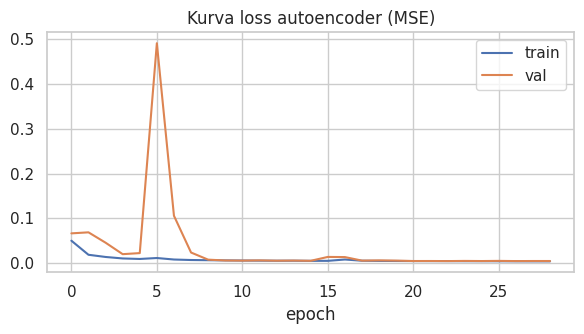

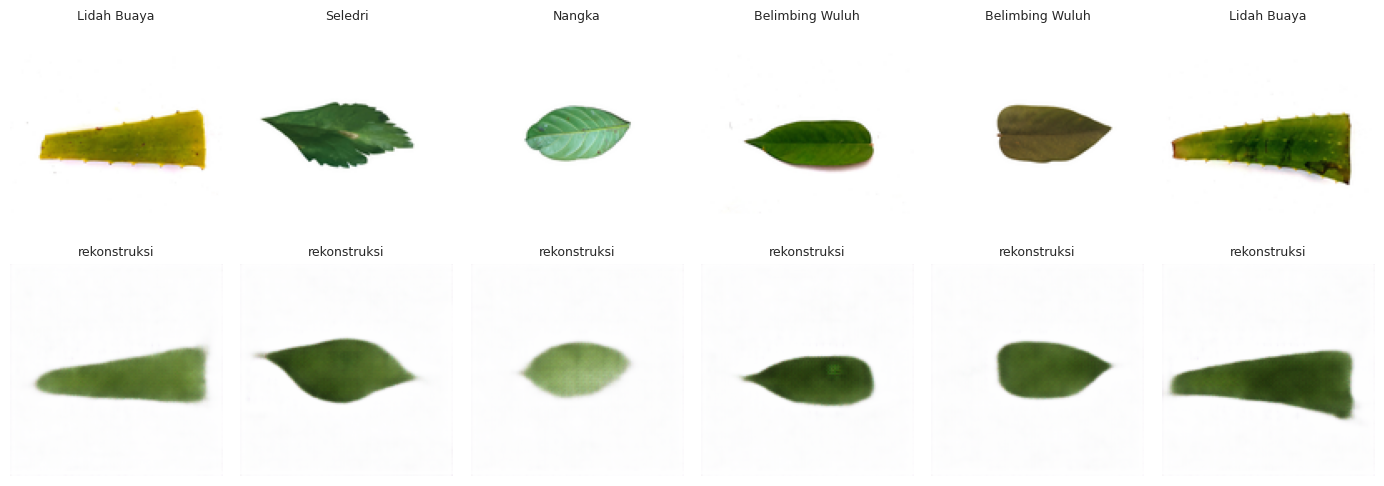

In [ ]:
from tensorflow.keras import layers, Model

try:
    df_clean = df_clean_cleansing.copy()
except NameError:
    raise NameError("Jalankan SEL 1 (Data Cleansing) terlebih dahulu.")

for _n, _v in dict(HAPUS_ANOMALI_AE=False, DROP_ANOMALI_FILES=[], KEEP_ANOMALI_FILES=[],
                   MAKS_PERSEN=0.03).items():
    globals().setdefault(_n, _v)

AUTOTUNE = tf.data.AUTOTUNE
AE_SIZE = 128          # citra diperkecil agar pelatihan cepat
LATENT = 128           # dimensi bottleneck
AE_EPOCHS = 40
AE_BATCH = 32
AE_Z_THR = 3.5         # ambang robust z-score per kelas (naikkan jika terlalu banyak anomali)
RETRAIN_AE = False     # True = paksa latih ulang

_ae_key = tuple(df_clean["path"])
_cached = (not RETRAIN_AE) and globals().get("_AE_KEY") == _ae_key and "autoencoder" in globals()
rng_ae = np.random.default_rng(SEED)

def load_u8(p):
    return np.asarray(letterbox(p, size=AE_SIZE), dtype="uint8")

def build_autoencoder():
    inp = layers.Input((AE_SIZE, AE_SIZE, 3))
    x = layers.Rescaling(1 / 255.0)(inp)
    for f in (32, 64, 128, 256):                        # 128 -> 8
        x = layers.Conv2D(f, 3, strides=2, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
    x = layers.Flatten()(x)
    z = layers.Dense(LATENT, name="latent")(x)          # bottleneck
    x = layers.Dense(8 * 8 * 256, activation="relu")(z)
    x = layers.Reshape((8, 8, 256))(x)
    for f in (256, 128, 64, 32):                        # 8 -> 128
        x = layers.Conv2DTranspose(f, 3, strides=2, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
    out = layers.Conv2D(3, 3, padding="same", activation="sigmoid")(x)
    return Model(inp, out, name="autoencoder")

def make_ae_ds(idx, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(X_ae[idx])
    ds = ds.map(lambda x: (x, tf.cast(x, tf.float32) / 255.0), num_parallel_calls=AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(len(idx), seed=SEED)
    return ds.batch(AE_BATCH).prefetch(AUTOTUNE)

if _cached:
    print("  ")
else:
    tf.keras.utils.set_random_seed(SEED)
    with ThreadPoolExecutor(8) as ex:
        X_ae = np.stack(list(ex.map(load_u8, df_clean["path"])))    # urutan = urutan df_clean
    print("X_ae:", X_ae.shape, X_ae.dtype)

    autoencoder = build_autoencoder()
    autoencoder.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")

    perm = rng_ae.permutation(len(X_ae))
    n_val = int(0.1 * len(X_ae))
    val_idx, tr_idx = perm[:n_val], perm[n_val:]
    hist = autoencoder.fit(
        make_ae_ds(tr_idx, shuffle=True), validation_data=make_ae_ds(val_idx),
        epochs=AE_EPOCHS, verbose=2,
        callbacks=[tf.keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True),
                   tf.keras.callbacks.ReduceLROnPlateau(patience=3, factor=0.5)])
    plt.figure(figsize=(6, 3.5))
    plt.plot(hist.history["loss"], label="train")
    plt.plot(hist.history["val_loss"], label="val")
    plt.title("Kurva loss autoencoder (MSE)"); plt.xlabel("epoch"); plt.legend()
    plt.tight_layout(); plt.show()
    _AE_KEY = _ae_key

# ---- Contoh rekonstruksi (atas = asli, bawah = rekonstruksi) ----
idx6 = rng_ae.choice(len(X_ae), 6, replace=False)
rec6 = autoencoder.predict(X_ae[idx6], verbose=0)
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for j, i in enumerate(idx6):
    axes[0, j].imshow(X_ae[i]); axes[0, j].set_title(df_clean.label.iloc[i], fontsize=9)
    axes[1, j].imshow(rec6[j]); axes[1, j].set_title("rekonstruksi", fontsize=9)
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# ---- Reconstruction error per citra ----
errs = []
for i in range(0, len(X_ae), 128):
    xb = X_ae[i:i + 128]
    rec = autoencoder.predict(xb, verbose=0)
    errs.append(((rec - xb / 255.0) ** 2).mean(axis=(1, 2, 3)))
df_clean["ae_error"] = np.concatenate(errs)

Anomali autoencoder: 103 dari 3422 (3.0%)


label,Belimbing Wuluh,Jambu Biji,Jeruk Nipis,Kemangi,Lidah Buaya,Nangka,Pandan,Pepaya,Seledri,Sirih
anomali_AE,11,5,2,5,29,12,13,0,8,18


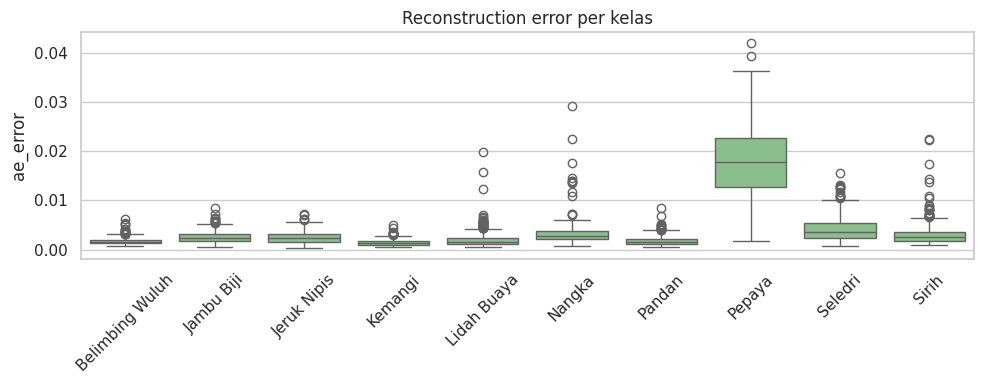

In [ ]:
# ---- Anomali = error jauh di atas normal kelasnya (robust z-score) ----
def robust_z(s):
    med = s.median()
    mad = (s - med).abs().median() + 1e-12
    return 0.6745 * (s - med) / mad

df_clean["ae_z"] = df_clean.groupby("label")["ae_error"].transform(robust_z)
df_clean["ae_outlier"] = df_clean["ae_z"] > AE_Z_THR

print(f"Anomali autoencoder: {int(df_clean.ae_outlier.sum())} dari {len(df_clean)} "
      f"({df_clean.ae_outlier.mean():.1%})")
display(df_clean.groupby("label")["ae_outlier"].sum().reindex(CLASS_NAMES).to_frame("anomali_AE").T)

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=df_clean, x="label", y="ae_error", color="#81C784", ax=ax, order=CLASS_NAMES)
ax.set_title("Reconstruction error per kelas"); ax.set_xlabel("")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

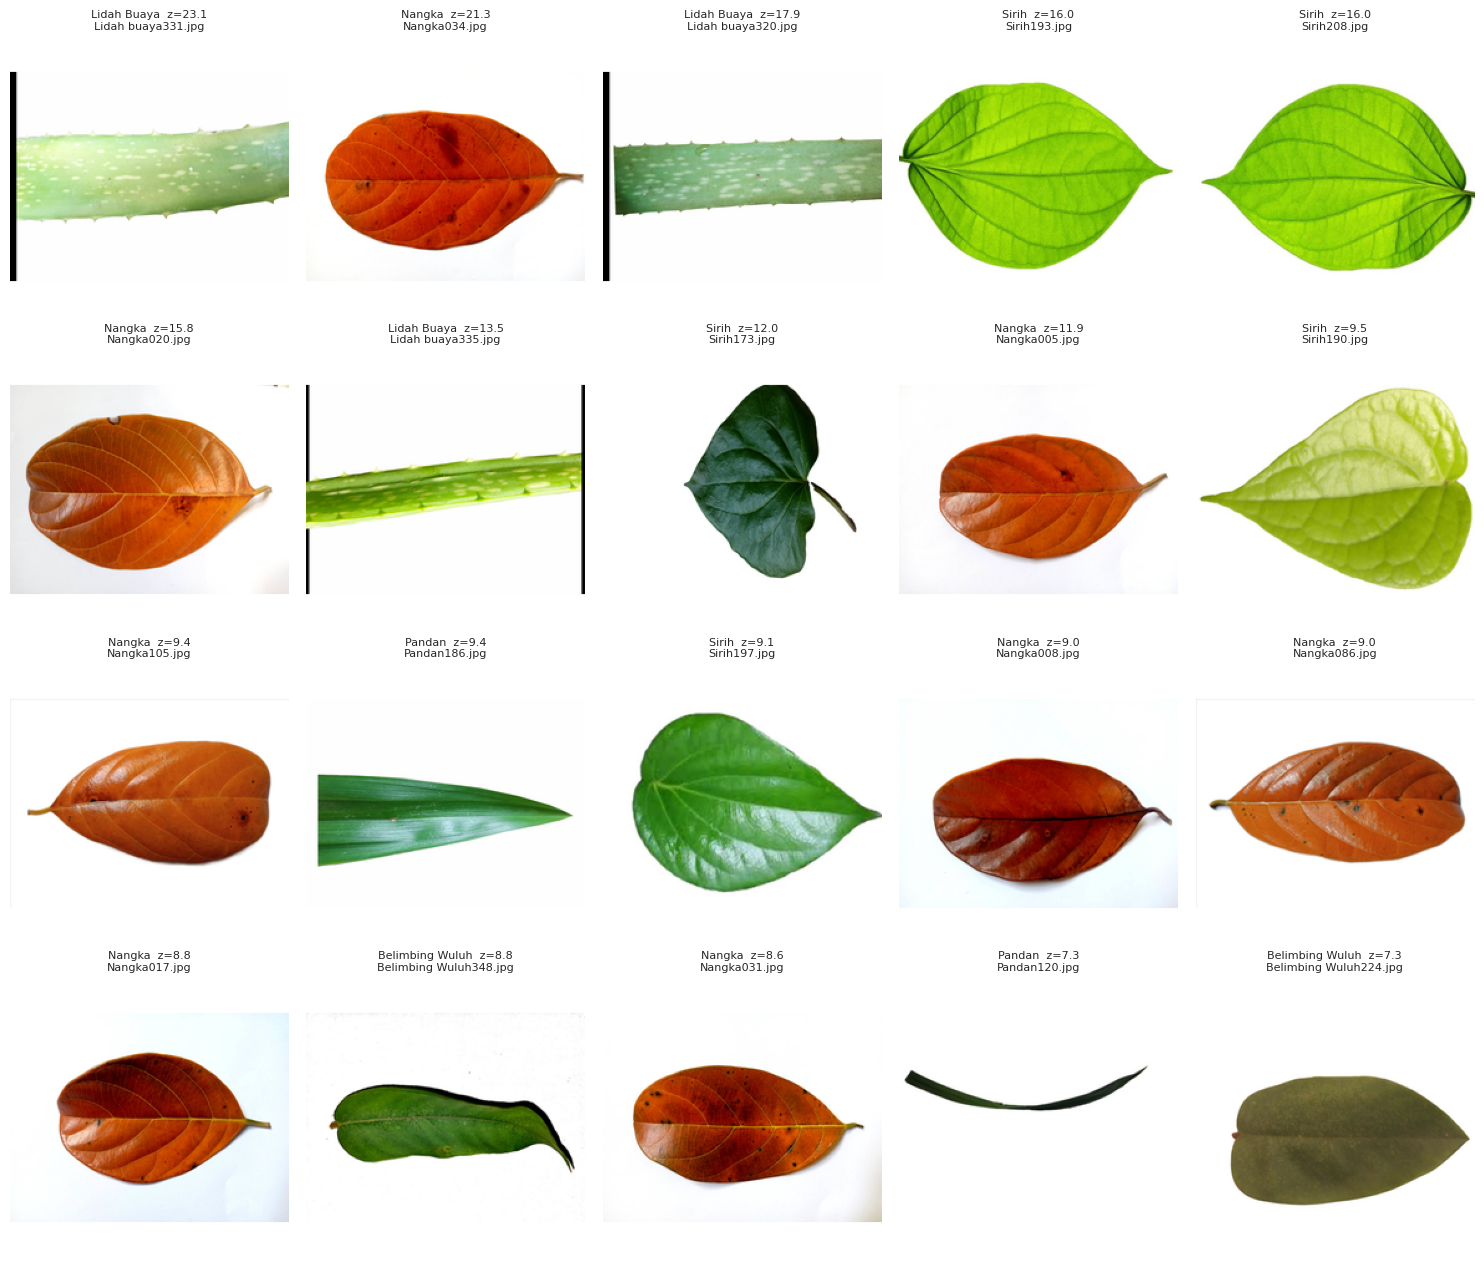

In [ ]:
# ---- Tinjauan visual: 20 citra dengan error tertinggi ----
top = df_clean[df_clean.ae_outlier].sort_values("ae_z", ascending=False).head(20)
if len(top):
    cols = 5; rows_ = int(np.ceil(len(top) / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(cols * 3, rows_ * 3.2), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, r in zip(axes.ravel(), top.itertuples()):
        ax.imshow(letterbox(r.path))
        ax.set_title(f"{r.label}  z={r.ae_z:.1f}\n{r.filename}", fontsize=8)
    plt.tight_layout(); plt.show()

In [ ]:

# ---- Tabel anomali (salin 'key' yang PASTI rusak/tidak layak ke DROP_ANOMALI_FILES) ----
anom_tbl = df_clean[df_clean.ae_outlier].sort_values("ae_z", ascending=False).copy()
anom_tbl["key"] = anom_tbl["label"] + "/" + anom_tbl["filename"]
display(anom_tbl[["key", "ae_error", "ae_z"]].round(4))


,key,ae_error,ae_z
1702,Lidah Buaya/Lidah buaya331.jpg,0.0199,23.0951
1755,Nangka/Nangka034.jpg,0.0293,21.2553
1691,Lidah Buaya/Lidah buaya320.jpg,0.0157,17.8526
3267,Sirih/Sirih193.jpg,0.0224,16.0478
3280,Sirih/Sirih208.jpg,0.0223,15.9538
...,...,...,...
1715,Lidah Buaya/Lidah buaya344.jpg,0.0044,3.5415
1804,Nangka/Nangka084.jpg,0.0072,3.5216
2372,Pandan/Pandan307.jpg,0.0040,3.5183
1432,Lidah Buaya/Lidah Buaya061.jpg,0.0044,3.5080


In [ ]:
# ---- Keputusan penghapusan ----
key = df_clean["label"] + "/" + df_clean["filename"]
salah_ketik = [k for k in list(DROP_ANOMALI_FILES) + list(KEEP_ANOMALI_FILES) if k not in set(key)]
print("Nama di DROP_ANOMALI_FILES/KEEP_ANOMALI_FILES yang tidak ditemukan:", salah_ketik, "(harus [])")

auto_ae = HAPUS_ANOMALI_AE
frac_ae = float(df_clean["ae_outlier"].mean())
if auto_ae and frac_ae > MAKS_PERSEN:
    print(f"PERINGATAN: anomali = {frac_ae:.1%} (> {MAKS_PERSEN:.0%}). Penghapusan otomatis DIBATALKAN.")
    auto_ae = False

no_drop = pd.Series(False, index=df_clean.index)
drop_ae = (df_clean["ae_outlier"] & ~key.isin(KEEP_ANOMALI_FILES)) if auto_ae else no_drop
drop_ae_manual = key.isin(DROP_ANOMALI_FILES) & ~drop_ae
n_ae, n_ae_manual = int(drop_ae.sum()), int(drop_ae_manual.sum())
n_sebelum = len(df_clean)
df_clean = df_clean[~(drop_ae | drop_ae_manual)].reset_index(drop=True)

ringkasan_final = pd.DataFrame({
    "tahap": ["Data setelah cleansing (SEL 1)", "Anomali ditandai autoencoder",
              "Anomali dibuang (otomatis)", "Anomali dibuang (manual)", "DATA BERSIH AKHIR"],
    "jumlah": [n_sebelum, len(anom_tbl),
               n_ae, n_ae_manual, len(df_clean)],
})
display(ringkasan_final)
display(df_clean["label"].value_counts().reindex(CLASS_NAMES).to_frame("jumlah_akhir").T)

Nama di DROP_ANOMALI_FILES/KEEP_ANOMALI_FILES yang tidak ditemukan: [] (harus [])


,tahap,jumlah
0,Data setelah cleansing (SEL 1),3422
1,Anomali ditandai autoencoder,103
2,Anomali dibuang (otomatis),0
3,Anomali dibuang (manual),0
4,DATA BERSIH AKHIR,3422


label,Belimbing Wuluh,Jambu Biji,Jeruk Nipis,Kemangi,Lidah Buaya,Nangka,Pandan,Pepaya,Seledri,Sirih
jumlah_akhir,349,347,326,350,350,345,349,316,349,341


**Image standardization**

In [ ]:
# mengubah semua gambar ke format seragam (RGB, 224x224, JPEG) dan menyimpannya dalam struktur
train_df, tmp_df = train_test_split(df_clean, test_size=1 - SPLIT[0],
                                    stratify=df_clean["label"], random_state=SEED)
val_df, test_df  = train_test_split(tmp_df, test_size=SPLIT[2] / (SPLIT[1] + SPLIT[2]),
                                    stratify=tmp_df["label"], random_state=SEED)
df_split = pd.concat([train_df.assign(split="train"),
                      val_df.assign(split="val"),
                      test_df.assign(split="test")], ignore_index=True)

tabel = pd.crosstab(df_split["label"], df_split["split"])[["train", "val", "test"]]
tabel["total"] = tabel.sum(axis=1)
tabel.loc["TOTAL"] = tabel.sum()
display(tabel)

def process_row(r):
    out = PREP_DIR / r.split / r.label / (Path(r.filename).stem + ".jpg")
    out.parent.mkdir(parents=True, exist_ok=True)
    letterbox(r.path).save(out, quality=95)
    return str(out)

if PREP_DIR.exists():
    shutil.rmtree(PREP_DIR)
with ThreadPoolExecutor(8) as ex:
    df_split["prep_path"] = list(ex.map(process_row, df_split.itertuples()))
for s in ["train", "val", "test"]:
    print(f"{s:5s}: {sum(1 for _ in (PREP_DIR / s).rglob('*.jpg'))} citra")

split,train,val,test,total
label,,,,
Belimbing Wuluh,279,35,35,349
Jambu Biji,277,35,35,347
Jeruk Nipis,261,32,33,326
Kemangi,280,35,35,350
Lidah Buaya,280,35,35,350
Nangka,276,34,35,345
Pandan,279,35,35,349
Pepaya,253,32,31,316
Seledri,279,35,35,349


train: 2737 citra
val  : 342 citra
test : 343 citra


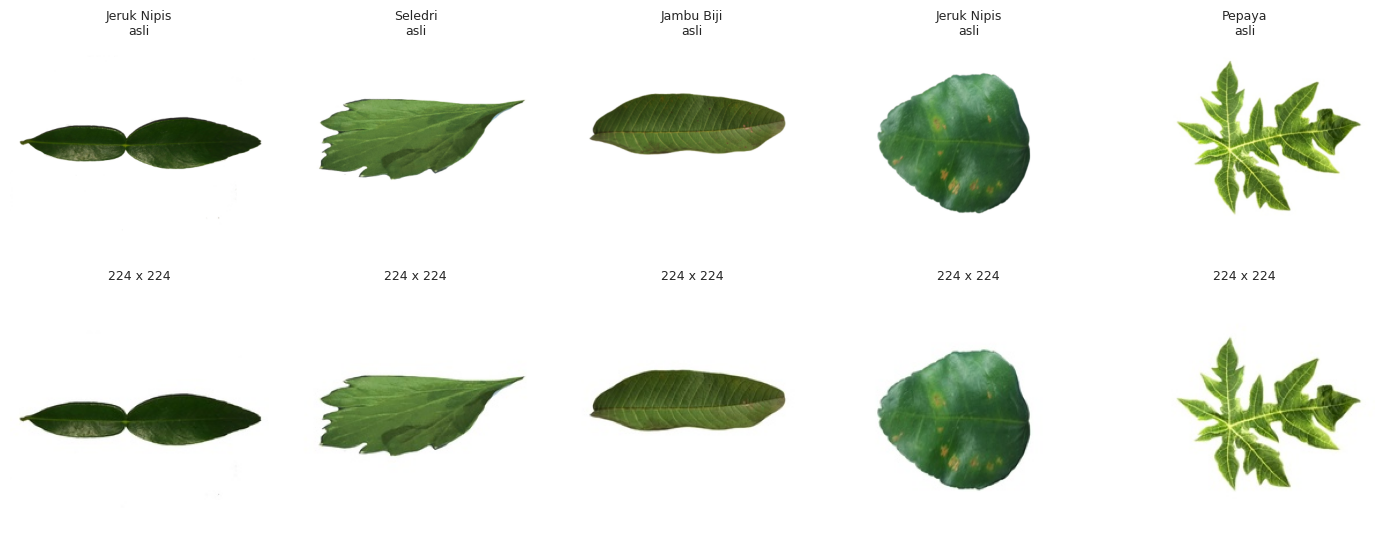

In [ ]:
# Pemeriksaan visual() baris atas = gambar asli, baris bawah = hasil 224x224)
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for j, r in enumerate(df_split.sample(5, random_state=SEED).itertuples()):
    o = Image.open(r.path); o.draft("RGB", (400, 300))
    axes[0, j].imshow(ImageOps.exif_transpose(o)); axes[0, j].set_title(f"{r.label}\nasli", fontsize=9)
    axes[1, j].imshow(Image.open(r.prep_path));    axes[1, j].set_title("224 x 224", fontsize=9)
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

**Augmentasi**

In [ ]:
AUG_TARGET = 400    # jumlah citra latih per kelas setelah augmentasi (harus > jumlah train terbesar)
AUG_BATCH = 32

# variasi acak: posisi, orientasi, zoom, kontras, kecerahan
augmenter = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.25, fill_mode="constant", fill_value=255.0),    # hingga +-90 derajat
    tf.keras.layers.RandomZoom((-0.15, 0.15), fill_mode="constant", fill_value=255.0),
    tf.keras.layers.RandomContrast(0.2),
    tf.keras.layers.RandomBrightness(0.2, value_range=(0, 255)),
], name="augmentasi")

def load_prep_f32(p):
    return np.asarray(Image.open(p).convert("RGB"), dtype="float32")

rng_aug = np.random.default_rng(SEED)
train_orig = df_split[df_split.split == "train"]
aug_rows = []

for cls in CLASS_NAMES:
    src = train_orig[train_orig.label == cls].reset_index(drop=True)
    n_need = AUG_TARGET - len(src)
    assert n_need > 0, f"AUG_TARGET ({AUG_TARGET}) harus lebih besar dari jumlah train kelas {cls} ({len(src)})"

    # sumber dipilih bergilir agar setiap citra asli terpakai merata
    n_rounds = int(np.ceil(n_need / len(src)))
    order = np.concatenate([rng_aug.permutation(len(src)) for _ in range(n_rounds)])[:n_need]

    for start in range(0, n_need, AUG_BATCH):
        idxs = order[start:start + AUG_BATCH]
        batch = np.stack([load_prep_f32(src["prep_path"].iloc[i]) for i in idxs])
        aug = augmenter(batch, training=True).numpy().clip(0, 255).astype("uint8")
        for k, (i, a) in enumerate(zip(idxs, aug)):
            n = start + k
            r = src.iloc[i].to_dict()
            out = PREP_DIR / "train" / cls / f"{Path(r['filename']).stem}_aug{n:03d}.jpg"
            Image.fromarray(a).save(out, quality=95)
            r.update(prep_path=str(out), filename=out.name, is_aug=True, source_path=r["prep_path"])
            aug_rows.append(r)

df_aug = pd.DataFrame(aug_rows)
df_final = pd.concat([df_split, df_aug], ignore_index=True)

tab = (pd.crosstab(df_final["label"], [df_final["split"], df_final["is_aug"]])
         .reindex(CLASS_NAMES))
display(tab)
print(df_final[df_final.split == "train"].groupby("label").size().reindex(CLASS_NAMES).to_frame("train_setelah_augmentasi").T)

split,train
is_aug,True
label,
Belimbing Wuluh,121
Jambu Biji,123
Jeruk Nipis,139
Kemangi,120
Lidah Buaya,120
Nangka,124
Pandan,121
Pepaya,147


label                     Belimbing Wuluh  Jambu Biji  Jeruk Nipis  Kemangi  \
train_setelah_augmentasi              400         400          400      400   

label                     Lidah Buaya  Nangka  Pandan  Pepaya  Seledri  Sirih  
train_setelah_augmentasi          400     400     400     400      400    400  


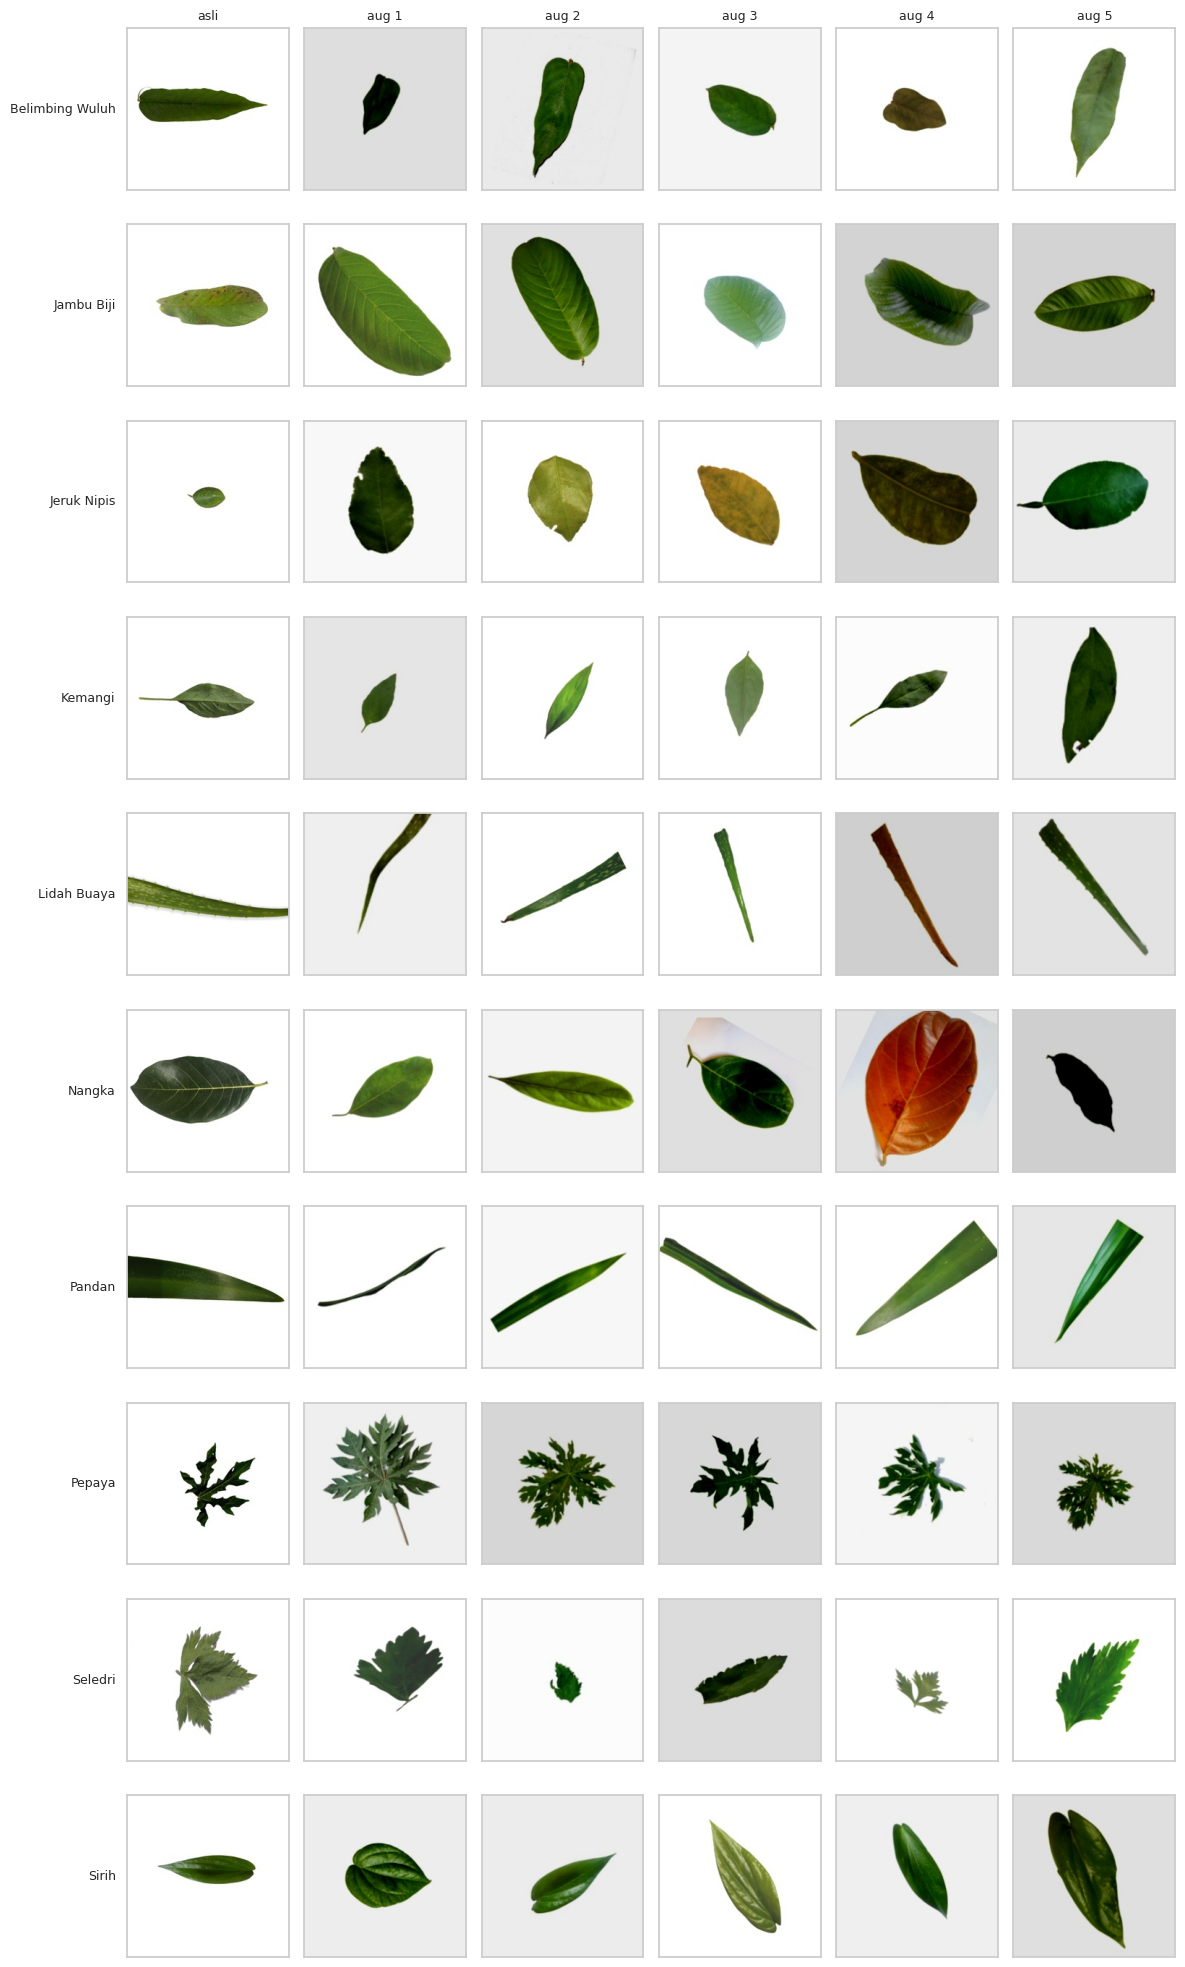

In [ ]:
# Visualisasi semua kelas: kolom 1 = citra asli (sumber), kolom 2-6 = hasil augmentasi
fig, axes = plt.subplots(len(CLASS_NAMES), 6, figsize=(12, 2 * len(CLASS_NAMES)))
for r_i, cls in enumerate(CLASS_NAMES):
    a_cls = df_aug[df_aug.label == cls]
    axes[r_i, 0].imshow(Image.open(a_cls["source_path"].iloc[0]))
    axes[r_i, 0].set_ylabel(cls, rotation=0, ha="right", va="center", fontsize=9, labelpad=8)
    for c, p in enumerate(a_cls["prep_path"].sample(5, random_state=SEED), start=1):
        axes[r_i, c].imshow(Image.open(p))
    for c in range(6):
        axes[r_i, c].set_xticks([]); axes[r_i, c].set_yticks([])
        if r_i == 0:
            axes[r_i, c].set_title("asli" if c == 0 else f"aug {c}", fontsize=9)
plt.tight_layout(); plt.show()

**TRANSFORMASI**

In [ ]:
from tensorflow.keras.applications import densenet
AUTOTUNE = tf.data.AUTOTUNE # mengatur paralelisme otomatis

def load_base(split):
    ds = tf.keras.utils.image_dataset_from_directory(
        PREP_DIR / split, labels="inferred", label_mode="categorical",
        class_names=CLASS_NAMES, image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=None, shuffle=False)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.uint8), y), num_parallel_calls=AUTOTUNE)
    return ds.cache(), len(ds)

BASE, N_IMAGES = {}, {}
for s in ["train", "val", "test"]:
    BASE[s], N_IMAGES[s] = load_base(s)

def make_dataset(split, preprocess_fn, training=False):
    ds = BASE[split]
    if training:
        ds = ds.shuffle(N_IMAGES[split], seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (augmenter(x, training=True), y), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocess_fn(x), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

# Normalisasi
PREPROCESS = {
    "DenseNet121"         : densenet.preprocess_input, # model acuan
    "Lightweight_DenseNet": lambda x: x,               # model pembanding
}
datasets = {name: {"train": make_dataset("train", fn, training=True),
                   "val"  : make_dataset("val", fn),
                   "test" : make_dataset("test", fn)}
            for name, fn in PREPROCESS.items()}

y_train = train_df["label"].map({c: i for i, c in enumerate(CLASS_NAMES)}).values
cw = compute_class_weight("balanced", classes=np.arange(len(CLASS_NAMES)), y=y_train)
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(cw)}

Found 4000 files belonging to 10 classes.
Found 342 files belonging to 10 classes.
Found 343 files belonging to 10 classes.


**Validasi**

In [ ]:
SPL = ["train", "val", "test"]
m = df_final.copy()
m["is_aug"] = m["is_aug"].eq(True)
orig, aug = m[~m["is_aug"]], m[m["is_aug"]]
checks = []
def chk(grup, nama, ok, info=""):
    checks.append((grup, bool(ok), nama, info))

# File dan citra
def cek_img(p):
    try:
        with Image.open(p) as im:
            ok = im.size == (IMG_SIZE, IMG_SIZE) and im.mode == "RGB"
            im.verify()
        return ok
    except Exception:
        return False

with ThreadPoolExecutor(8) as ex:
    img_ok = list(ex.map(cek_img, m["prep_path"]))
n_files = sum(1 for _ in PREP_DIR.rglob("*.jpg"))
G = "File dan citra"
chk(G, "Jumlah file JPG = baris tabel", n_files == len(m), f"{n_files} vs {len(m)}")
chk(G, "Semua citra terbaca, 224x224 RGB", all(img_ok), f"{len(img_ok) - sum(img_ok)} bermasalah")

# Label dan split
G = "Label dan split"
chk(G, "Label & split lengkap, 10 kelas/subset",
    m[["label", "split"]].notna().all().all() and set(m["split"]) <= set(SPL)
    and all(m[m["split"] == s]["label"].nunique() == len(CLASS_NAMES) for s in SPL))
prop = orig["split"].value_counts(normalize=True)
chk(G, "Proporsi 80/10/10 (±1%, citra asli)",
    all(abs(prop.get(s, 0) - t) <= 0.01 for s, t in zip(SPL, SPLIT)),
    " / ".join(f"{s} {prop.get(s, 0):.0%}" for s in SPL))
chk(G, "Struktur folder kelas sesuai",
    all(sorted(p.name for p in (PREP_DIR / s).iterdir() if p.is_dir()) == sorted(CLASS_NAMES) for s in SPL))

# Augmentasi
G = "Augmentasi"
per_cls = m[m["split"] == "train"].groupby("label").size().reindex(CLASS_NAMES, fill_value=0)
chk(G, "Hanya di data train", (aug["split"] == "train").all(), f"{len(aug)} citra augmentasi")
chk(G, "Semua 10 kelas diaugmentasi",
    (aug.groupby("label").size().reindex(CLASS_NAMES, fill_value=0) > 0).all())
chk(G, f"Train per kelas = {AUG_TARGET}", (per_cls == AUG_TARGET).all(),
    f"min {per_cls.min()} / maks {per_cls.max()}")

# Kebocoran dan duplikasi
G = "Kebocoran dan duplikasi"
leak = int((m.groupby("md5")["split"].nunique() > 1).sum())
chk(G, "Tidak ada MD5 yang sama antar subset", leak == 0, f"{leak} hash bocor")
chk(G, "Tidak ada path ganda", not m["prep_path"].duplicated().any())

# Pipeline TensorFlow
G = "Pipeline TensorFlow"
chk(G, "Jumlah citra pipeline = tabel",
    all(N_IMAGES[s] == int((m["split"] == s).sum()) for s in SPL),
    " / ".join(f"{s} {N_IMAGES[s]}" for s in SPL))
for name, d in datasets.items():
    xb, yb = next(iter(d["train"]))
    x, y_ = xb.numpy(), yb.numpy()
    ok = (x.shape[1:] == (IMG_SIZE, IMG_SIZE, 3) and np.isfinite(x).all()
          and y_.shape[1] == len(CLASS_NAMES) and np.allclose(y_.sum(1), 1))
    chk(G, f"Batch {name}", ok, f"{tuple(x.shape)}, nilai {x.min():.1f} s/d {x.max():.1f}")

# Hasil: tabel pemeriksaan
res = pd.DataFrame(checks, columns=["Kelompok", "ok", "Pemeriksaan", "Keterangan"])
res["Hasil"] = np.where(res["ok"], "Lulus", "Gagal")
gagal = int((~res["ok"]).sum())
status = "LULUS SEMUA VALIDASI" if gagal == 0 else f"GAGAL ({gagal} pemeriksaan)"

display(res[["Kelompok", "Pemeriksaan", "Hasil", "Keterangan"]].style.hide(axis="index")
        .set_properties(**{"text-align": "left"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
        .set_caption(f"STATUS: {status}   [{len(res) - gagal}/{len(res)} lulus]"))

Kelompok,Pemeriksaan,Hasil,Keterangan
File dan citra,Jumlah file JPG = baris tabel,Lulus,4685 vs 4685
File dan citra,"Semua citra terbaca, 224x224 RGB",Lulus,0 bermasalah
Label dan split,"Label & split lengkap, 10 kelas/subset",Lulus,
Label dan split,"Proporsi 80/10/10 (±1%, citra asli)",Lulus,train 80% / val 10% / test 10%
Label dan split,Struktur folder kelas sesuai,Lulus,
Augmentasi,Hanya di data train,Lulus,1263 citra augmentasi
Augmentasi,Semua 10 kelas diaugmentasi,Lulus,
Augmentasi,Train per kelas = 400,Lulus,min 400 / maks 400
Kebocoran dan duplikasi,Tidak ada MD5 yang sama antar subset,Lulus,0 hash bocor
Kebocoran dan duplikasi,Tidak ada path ganda,Lulus,


In [ ]:
# Tabel jumlah citra per kelas
tab = pd.DataFrame({
    "train_asli": orig[orig["split"] == "train"].groupby("label").size(),
    "train_aug" : aug.groupby("label").size(),
    "val"       : m[m["split"] == "val"].groupby("label").size(),
    "test"      : m[m["split"] == "test"].groupby("label").size(),
}).reindex(CLASS_NAMES).fillna(0).astype(int)
tab["train_total"] = tab["train_asli"] + tab["train_aug"]
tab.loc["TOTAL"] = tab.sum()
display(tab.style.set_caption("Jumlah citra per kelas"))

,train_asli,train_aug,val,test,train_total
label,,,,,
Belimbing Wuluh,279,121,35,35,400
Jambu Biji,277,123,35,35,400
Jeruk Nipis,261,139,32,33,400
Kemangi,280,120,35,35,400
Lidah Buaya,280,120,35,35,400
Nangka,276,124,34,35,400
Pandan,279,121,35,35,400
Pepaya,253,147,32,31,400
Seledri,279,121,35,35,400


## CRISP-DM Phase 4: Modeling — DenseNet-121

Menggunakan DenseNet-121 pretrained ImageNet untuk klasifikasi 10 jenis daun melalui warm-up classifier dan fine-tuning blok akhir. Jalankan Phase 1–3 terlebih dahulu, lalu ikuti cell berikut secara berurutan.


### Hubungkan Google Drive

Hubungkan Drive sebelum membuat run agar konfigurasi, checkpoint, dan log disimpan secara persisten.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Simpan atau pulihkan handoff Phase 3

Setelah QC Phase 3 lulus, jalankan dengan `HANDOFF_ACTION = "save"` untuk menyimpan citra dan tabel ke Drive. Setelah runtime reset, hubungkan Drive, ganti menjadi `"restore"`, jalankan cell ini, lalu jalankan cell TRANSFORMASI Phase 3 dan lanjutkan ke handoff modeling. Arsip tidak menimpa dataset yang sudah ada.

In [ ]:
# Simpan handoff setelah QC lulus, atau pulihkan setelah runtime reset.
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
import io, json, os, random, shutil, tempfile, zipfile
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

assert os.path.ismount('/content/drive'), 'Jalankan sel Google Drive terlebih dahulu.'
HANDOFF_ACTION = 'restore'  # Ubah menjadi 'restore' setelah runtime reset.
handoff_dir = Path('/content/drive/MyDrive/FGD6/handoff')

if HANDOFF_ACTION == 'save':
    assert 'checks' in globals() and checks and all(row[1] for row in checks), 'QC Phase 3 harus lulus.'
    assert PREP_DIR.is_dir() and len(df_final) == sum(N_IMAGES.values())
    expected = {Path(p).resolve() for p in df_final['prep_path']}
    actual = {p.resolve() for p in PREP_DIR.rglob('*.jpg')}
    assert len(expected) == len(df_final) and expected == actual, 'File handoff tidak cocok dengan tabel.'
    for p in expected:
        p.relative_to(PREP_DIR.resolve())
    handoff_dir.mkdir(parents=True, exist_ok=True)
    handoff_final = handoff_dir / (datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ') + '.zip')
    handoff_path = handoff_final.with_suffix('.partial')
    metadata = {
        'classes': list(CLASS_NAMES), 'image_size': IMG_SIZE, 'batch': BATCH,
        'seed': SEED, 'dataset_file_id': FILE_ID, 'split': list(SPLIT),
        'counts': {s: int(N_IMAGES[s]) for s in ('train', 'val', 'test')},
        'checks': [list(row) for row in checks], 'augmenter': augmenter.to_json(),
    }
    with zipfile.ZipFile(handoff_path, 'x', compression=zipfile.ZIP_STORED) as archive:
        archive.writestr('metadata.json', json.dumps(metadata, ensure_ascii=False))
        archive.writestr('df_final.csv', df_final.to_csv(index=False))
        archive.writestr('train_df.csv', train_df.to_csv(index=False))
        for image_path in sorted(expected):
            archive.write(image_path, 'images/' + image_path.relative_to(PREP_DIR.resolve()).as_posix())
    with zipfile.ZipFile(handoff_path) as archive:
        assert archive.testzip() is None, 'Arsip handoff gagal diperiksa.'
    handoff_path.rename(handoff_final)
    handoff_path = handoff_final
    print('Handoff disimpan:', handoff_path)

elif HANDOFF_ACTION == 'restore':
    handoff_files = sorted(handoff_dir.glob('*.zip'))
    assert handoff_files, 'Handoff belum tersedia di Drive; simpan setelah Phase 3 selesai.'
    handoff_path = handoff_files[-1]
    WORK_DIR = Path('/content/work')
    PREP_DIR = WORK_DIR / 'dataset_224'
    assert not PREP_DIR.exists(), 'Folder dataset sudah ada; jangan timpa. Gunakan runtime kosong.'
    with zipfile.ZipFile(handoff_path) as archive:
        assert archive.testzip() is None, 'Arsip handoff rusak.'
        metadata = json.loads(archive.read('metadata.json'))
        df_final = pd.read_csv(io.BytesIO(archive.read('df_final.csv')))
        train_df = pd.read_csv(io.BytesIO(archive.read('train_df.csv')))
        image_names = [n for n in archive.namelist() if n.startswith('images/') and not n.endswith('/')]
        assert len(image_names) == len(df_final) == sum(metadata['counts'].values())
        assert len(image_names) == len(set(image_names))
        for name in image_names:
            path = PurePosixPath(name)
            assert len(path.parts) >= 4 and path.parts[0] == 'images' and '..' not in path.parts
        WORK_DIR.mkdir(parents=True, exist_ok=True)
        stage_dir = Path(tempfile.mkdtemp(prefix='handoff-', dir=WORK_DIR))
        try:
            for name in image_names:
                dest = stage_dir.joinpath(*PurePosixPath(name).parts[1:])
                dest.parent.mkdir(parents=True, exist_ok=True)
                with archive.open(name) as src, dest.open('xb') as target:
                    shutil.copyfileobj(src, target)
            assert all(len(list((stage_dir / s).rglob('*.jpg'))) == metadata['counts'][s] for s in ('train', 'val', 'test'))
            stage_dir.rename(PREP_DIR)
        finally:
            if stage_dir.exists():
                shutil.rmtree(stage_dir)
    CLASS_NAMES = metadata['classes']
    IMG_SIZE, BATCH, SEED = metadata['image_size'], metadata['batch'], metadata['seed']
    FILE_ID, SPLIT = metadata['dataset_file_id'], tuple(metadata['split'])
    checks = metadata['checks']
    assert checks and all(row[1] for row in checks) and len(CLASS_NAMES) == 10
    assert all((PREP_DIR / s / cls).is_dir() for s in ('train', 'val', 'test') for cls in CLASS_NAMES)
    assert all(len(list((PREP_DIR / s).rglob('*.jpg'))) == metadata['counts'][s] for s in ('train', 'val', 'test'))
    random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
    augmenter = tf.keras.models.model_from_json(metadata['augmenter'])
    print('Handoff dipulihkan:', handoff_path)
    print('Jalankan sel TRANSFORMASI Phase 3, lalu lanjutkan ke Data pipeline dan handoff.')
else:
    raise ValueError("HANDOFF_ACTION harus 'save' atau 'restore'.")


Handoff dipulihkan: /content/drive/MyDrive/FGD6/handoff/20261028T104133_556236Z.zip
Jalankan sel TRANSFORMASI Phase 3, lalu lanjutkan ke Data pipeline dan handoff.


### Data pipeline dan handoff

Memakai hasil Phase 3 yang sudah dibagi dan diproses. `train_dataset` dan `val_dataset` menjadi masukan training; preprocessing tidak diulang.

In [ ]:
# Menggunakan data Phase 3 yang sudah diproses tanpa mengulang preprocessing.
train_dataset = datasets["DenseNet121"]["train"]
val_dataset = datasets["DenseNet121"]["val"]

# Menampilkan ringkasan data yang akan diterima model.
print("Jumlah kelas:", len(CLASS_NAMES))
print("Nama kelas:", ", ".join(CLASS_NAMES))
print(f"Data train: {N_IMAGES['train']} gambar")
print(f"Data validation: {N_IMAGES['val']} gambar")
print(f"Ukuran input: {IMG_SIZE} x {IMG_SIZE} RGB | batch: {BATCH}")

Jumlah kelas: 10
Nama kelas: Belimbing Wuluh, Jambu Biji, Jeruk Nipis, Kemangi, Lidah Buaya, Nangka, Pandan, Pepaya, Seledri, Sirih
Data train: 4000 gambar
Data validation: 342 gambar
Ukuran input: 224 x 224 RGB | batch: 32


### Konfigurasi eksperimen

Mencatat seed, setelan training, perangkat, precision policy, dan arsip handoff ke `config.json` dalam folder run baru di Google Drive.

In [ ]:
# Menyimpan konfigurasi sebelum training dalam folder run baru.
from datetime import datetime, timezone
import platform
import time
import json
import tensorflow as tf

# Fallback definitions if session state was lost
SEED = globals().get('SEED', 42)
FILE_ID = globals().get('FILE_ID', '1jieheQOYqDga1FhBKQgs6tcwVX02uWQr')
IMG_SIZE = globals().get('IMG_SIZE', 224)
BATCH = globals().get('BATCH', 32)
CLASS_NAMES = globals().get('CLASS_NAMES', ['Belimbing Wuluh', 'Jambu Biji', 'Jeruk Nipis', 'Kemangi', 'Lidah Buaya', 'Nangka', 'Pandan', 'Pepaya', 'Seledri', 'Sirih'])
N_IMAGES = globals().get('N_IMAGES', {'train': 4000, 'val': 342})
WORK_DIR = globals().get('WORK_DIR', Path("/content/work"))

# Mixed precision mempercepat training pada GPU yang mendukung.
gpus = tf.config.list_physical_devices("GPU")
gpu_details = tf.config.experimental.get_device_details(gpus[0]) if gpus else {}
precision_policy = "mixed_float16" if gpu_details.get("compute_capability", (0, 0)) >= (7, 0) else "float32"
tf.keras.mixed_precision.set_global_policy(precision_policy)
tf.keras.utils.set_random_seed(SEED)

# Menggunakan WORK_DIR dari setup awal tanpa mengunduh dataset ulang.
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
from pathlib import Path
import os
assert os.path.ismount("/content/drive"), "Hubungkan Google Drive sebelum membuat run."
assert "handoff_path" in globals() and handoff_path.is_file(), "Simpan handoff Phase 3 terlebih dahulu."
RUNS_ROOT = Path("/content/drive/MyDrive/FGD6/runs")
run_dir = RUNS_ROOT / "DenseNet121" / run_id
run_dir.mkdir(parents=True, exist_ok=False)

# Setelan baseline: warm-up classifier, lalu fine-tuning blok conv5_.
config = {
    "model": "DenseNet121",
    "weights": "imagenet",
    "dataset_file_id": FILE_ID,
    "seed": SEED,
    "image_size": IMG_SIZE,
    "batch_size": BATCH,
    "classes": list(CLASS_NAMES),
    "train_images": N_IMAGES["train"],
    "validation_images": N_IMAGES["val"],
    "preprocessing": "RGB letterbox 224x224; densenet.preprocess_input pada pipeline; tanpa normalisasi ulang",
    "class_weight": None,  # Data train sudah seimbang setelah augmentasi.
    "dropout": 0.3,
    "loss": "categorical_crossentropy",
    "optimizer": "Adam",
    "warmup_epochs": 10,
    "warmup_learning_rate": 1e-3,
    "warmup_patience": 3,
    "finetune_epochs": 25,
    "finetune_learning_rate": 1e-5,
    "finetune_patience": 5,
    "finetune_block": "conv5_",
    "batchnorm_trainable": False,
    "checkpoint_monitor": "val_loss",
    "checkpoint_mode": "min",
    "precision_policy": precision_policy,
    "python_version": platform.python_version(),
    "tensorflow_version": tf.__version__,
    "keras_version": tf.keras.__version__,
    "gpu_name": gpu_details.get("device_name", gpus[0].name if gpus else "CPU"),
    "compute_capability": gpu_details.get("compute_capability"),
}
config["handoff_archive"] = str(handoff_path)
(run_dir / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print(f"Konfigurasi berhasil disimpan | {config['gpu_name']} | {precision_policy}")
print("Folder eksperimen:", run_dir)

Konfigurasi berhasil disimpan | CPU | float32
Folder eksperimen: /content/drive/MyDrive/FGD6/runs/DenseNet121/20261028T104136_712764Z


### Membangun DenseNet-121

Memuat backbone pretrained ImageNet tanpa classifier bawaan, lalu menambahkan global pooling, dropout, dan softmax untuk 10 kelas. Backbone dibekukan agar warm-up hanya melatih classifier baru.

In [ ]:
# Membuat DenseNet-121 ImageNet dengan classifier 10 kelas.
base_model = tf.keras.applications.DenseNet121(
    include_top=False,  # Mengganti classifier ImageNet dengan kelas daun.
    weights=config["weights"],
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)
base_model.trainable = False  # Warm-up hanya melatih classifier baru.

# Preprocessing sudah dilakukan di pipeline Phase 3.
inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
features = base_model(inputs, training=False)  # Statistik BatchNorm tetap beku saat fine-tuning.
features = tf.keras.layers.GlobalAveragePooling2D()(features)
features = tf.keras.layers.Dropout(config["dropout"])(features)
outputs = tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax", dtype="float32")(features)
model = tf.keras.Model(inputs, outputs, name="herbal_densenet121")

model.summary()


Model: "herbal_densenet121"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,047,754 (26.89 MB)

 Trainable params: 10,250 (40.04 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

### Warm-up classifier

Melatih classifier di atas backbone beku menggunakan data train. `val_loss` menentukan checkpoint terbaik dan early stopping menghentikan training saat validation tidak membaik.

In [ ]:
import time
import tensorflow as tf

# Menyiapkan backbone beku dan classifier baru untuk warm-up.
base_model = tf.keras.applications.DenseNet121(
    include_top=False,
    weights=config["weights"],
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
features = base_model(inputs, training=False)
features = tf.keras.layers.GlobalAveragePooling2D()(features)
features = tf.keras.layers.Dropout(config["dropout"])(features)
outputs = tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax", dtype="float32")(features)
# Mengompilasi model untuk meminimalkan loss dan memantau akurasi.


model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=config["warmup_learning_rate"]),
    loss=config["loss"],
    metrics=["accuracy"],
)

# Train the classifier with frozen ImageNet features
warmup_checkpoint = run_dir / "warmup_best.keras"
warmup_start = time.perf_counter()
history_warmup = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=config["warmup_epochs"],
    callbacks=[
        tf.keras.callbacks.ModelCheckpoint(
            str(warmup_checkpoint), monitor="val_loss", mode="min", save_best_only=True,
        ),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=config["warmup_patience"]),
        tf.keras.callbacks.CSVLogger(str(run_dir / "warmup.csv")),
        tf.keras.callbacks.TerminateOnNaN(),
    ],
)
warmup_seconds = time.perf_counter() - warmup_start
print(f"Warm-up selesai: {len(history_warmup.epoch)} epoch, {warmup_seconds:.1f} detik")

Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 457s 4s/step - accuracy: 0.5650 - loss: 1.3508 - val_accuracy: 0.8830 - val_loss: 0.5416
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 443s 4s/step - accuracy: 0.8250 - loss: 0.6317 - val_accuracy: 0.9211 - val_loss: 0.3300
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 437s 3s/step - accuracy: 0.8662 - loss: 0.4745 - val_accuracy: 0.9561 - val_loss: 0.2539
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 441s 4s/step - accuracy: 0.8860 - loss: 0.4110 - val_accuracy: 0.9415 - val_loss: 0.2321
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 441s 4s/step - accuracy: 0.8942 - loss: 0.3567 - val_accuracy: 0.9591 - val_loss: 0.1938
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 442s 4s/step - accuracy: 0.8970 - loss: 0.3330 - val_accuracy: 0.9561 - val_loss: 0.1770
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 431s 3s/step - accuracy: 0.9068 - loss: 0.3065 - val_accuracy: 0.9561 - val_loss: 0.1679
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 432s 3s/step - accuracy: 0.9105 - loss: 0.3061 - val_accu

### Membuka blok akhir untuk fine-tuning

Memuat checkpoint warm-up terbaik, membuka blok `conv5_`, dan menjaga BatchNormalization tetap beku. Model di-compile ulang dengan learning rate yang lebih kecil.

In [ ]:
# Memulai fine-tuning dari checkpoint warm-up terbaik.
model = tf.keras.models.load_model(warmup_checkpoint, compile=False)
base_model = model.get_layer("densenet121")
base_model.trainable = True
# Hanya conv5_ yang dibuka; statistik BatchNormalization tetap beku.
for layer in base_model.layers:
    layer.trainable = (
        layer.name.startswith(config["finetune_block"])
        and not isinstance(layer, tf.keras.layers.BatchNormalization)
    )

# Optimizer baru menggunakan learning rate lebih kecil.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=config["finetune_learning_rate"]),
    loss=config["loss"],
    metrics=["accuracy"],
)
print("Parameter fine-tuning:", sum(int(np.prod(weight.shape)) for weight in model.trainable_weights))


Parameter fine-tuning: 2140170


### Fine-tuning

Melatih classifier bersama blok `conv5_` dengan data train dan validation. Checkpoint terbaik dipilih dari `val_loss`; log epoch dan durasi disimpan untuk menelusuri eksperimen.

In [ ]:
# Menyesuaikan conv5_ dan classifier dengan learning rate kecil.
# Checkpoint terpisah menjaga hasil warm-up tetap tersedia.
finetune_checkpoint = run_dir / "finetune_best.keras"
finetune_start = time.perf_counter()
history_finetune = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=config["finetune_epochs"],
    callbacks=[
        tf.keras.callbacks.ModelCheckpoint(
            str(finetune_checkpoint), monitor="val_loss", mode="min", save_best_only=True,
        ),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=config["finetune_patience"]),
        tf.keras.callbacks.CSVLogger(str(run_dir / "finetune.csv")),
        tf.keras.callbacks.TerminateOnNaN(),
    ],
)
finetune_seconds = time.perf_counter() - finetune_start
print(f"Fine-tuning selesai: {len(history_finetune.epoch)} epoch, {finetune_seconds:.1f} detik")


Epoch 1/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 499s 4s/step - accuracy: 0.9185 - loss: 0.2508 - val_accuracy: 0.9620 - val_loss: 0.1260
Epoch 2/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 485s 4s/step - accuracy: 0.9355 - loss: 0.2035 - val_accuracy: 0.9591 - val_loss: 0.1183
Epoch 3/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 490s 4s/step - accuracy: 0.9373 - loss: 0.1893 - val_accuracy: 0.9561 - val_loss: 0.1132
Epoch 4/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 469s 4s/step - accuracy: 0.9435 - loss: 0.1790 - val_accuracy: 0.9620 - val_loss: 0.1143
Epoch 5/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 468s 4s/step - accuracy: 0.9480 - loss: 0.1630 - val_accuracy: 0.9708 - val_loss: 0.1042
Epoch 6/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 502s 4s/step - accuracy: 0.9440 - loss: 0.1644 - val_accuracy: 0.9678 - val_loss: 0.1028
Epoch 7/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 472s 4s/step - accuracy: 0.9513 - loss: 0.1471 - val_accuracy: 0.9678 - val_loss: 0.0973
Epoch 8/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 470s 4s/step - accuracy: 0.9498 - loss: 0.1493 - val_accu

### Memilih checkpoint berdasarkan validation

Membandingkan `val_loss` terendah dari warm-up dan fine-tuning, lalu memuat checkpoint terbaik untuk evaluasi validation. Hasil pemilihan dicatat; data test tidak digunakan untuk memilih model.

In [ ]:
import json
import numpy as np
import pandas as pd
import tensorflow as tf

# D07 hanya memilih checkpoint jika log dan bobot dari kedua tahap masih tersedia.
artifact_names = ("warmup.csv", "finetune.csv", "warmup_best.keras", "finetune_best.keras")
artifacts_ready = "run_dir" in globals() and all((run_dir / name).is_file() for name in artifact_names)
if not artifacts_ready:
    print("Log atau checkpoint training tidak ditemukan. Jalankan kembali Phase 1–3 dan D01–D06 dalam runtime aktif.")
else:
    warmup_log = pd.read_csv(run_dir / "warmup.csv")
    finetune_log = pd.read_csv(run_dir / "finetune.csv")
    warmup_losses = warmup_log["val_loss"].to_numpy()
    finetune_losses = finetune_log["val_loss"].to_numpy()
    warmup_epoch = int(np.argmin(warmup_losses))
    finetune_epoch = int(np.argmin(finetune_losses))
    warmup_checkpoint = run_dir / "warmup_best.keras"
    finetune_checkpoint = run_dir / "finetune_best.keras"

    # Memilih val_loss terendah; jika seri, checkpoint warm-up dipertahankan.
    if finetune_losses[finetune_epoch] < warmup_losses[warmup_epoch]:
        selected_stage, selected_epoch = "fine-tuning", finetune_epoch + 1
        selected_checkpoint = finetune_checkpoint
        selected_val_loss = float(finetune_losses[finetune_epoch])
    else:
        selected_stage, selected_epoch = "warm-up", warmup_epoch + 1
        selected_checkpoint = warmup_checkpoint
        selected_val_loss = float(warmup_losses[warmup_epoch])

    # Memuat checkpoint terpilih untuk evaluasi validation berikutnya.
    selected_model_path = selected_checkpoint
    model = tf.keras.models.load_model(selected_model_path, compile=False)
    warmup_time = float(warmup_seconds) if "warmup_seconds" in globals() else None
    finetune_time = float(finetune_seconds) if "finetune_seconds" in globals() else None
    selection = {
        "stage": selected_stage,
        "epoch_in_stage": selected_epoch,
        "val_loss": selected_val_loss,
        "checkpoint": str(selected_checkpoint),
        "model_path": str(selected_model_path),
        "model_bytes": selected_model_path.stat().st_size,
        "parameters": model.count_params(),
        "warmup_seconds": warmup_time,
        "finetune_seconds": finetune_time,
        "total_training_seconds": warmup_time + finetune_time if warmup_time is not None and finetune_time is not None else None,
        "test_evaluated": False,
    }
    (run_dir / "selection.json").write_text(json.dumps(selection, indent=2), encoding="utf-8")
    print(f"Checkpoint terpilih: {selected_stage} | epoch {selected_epoch} | val_loss {selected_val_loss:.4f}")
    print("Model berhasil dimuat ulang:", selected_model_path)


Checkpoint terpilih: fine-tuning | epoch 25 | val_loss 0.0687
Model berhasil dimuat ulang: /content/drive/MyDrive/FGD6/runs/DenseNet121/20261028T104136_712764Z/finetune_best.keras


### Pulihkan run DenseNet-121 yang sudah tersimpan

Setelah mount Drive, pulihkan handoff dan jalankan TRANSFORMASI serta Data pipeline dan handoff. Jalankan cell ini untuk melihat daftar run. Isi `RECOVER_DENSENET_RUN` dengan nama folder yang dipilih, lalu jalankan lagi. Jika checkpoint final tersedia, model dimuat untuk melanjutkan ke LWDN tanpa melatih ulang DenseNet-121. Cell ini tidak melanjutkan epoch training yang terputus.

In [ ]:
# Memuat kembali run DenseNet-121 tanpa mengubah file run.
from pathlib import Path
import json
import tensorflow as tf

RECOVER_DENSENET_RUN = '20261028T104136_712764Z'  # Isi dengan nama folder run yang ditampilkan.
recovery_root = Path('/content/drive/MyDrive/FGD6/runs/DenseNet121')
available_runs = sorted(p for p in recovery_root.iterdir() if p.is_dir() and (p / 'config.json').is_file()) if recovery_root.is_dir() else []
if not RECOVER_DENSENET_RUN:
    print('Run tersedia:')
    for available_run in available_runs:
        print('-', available_run.name)
    if not available_runs:
        print('Belum ada run DenseNet-121 di Drive.')
    print('Isi RECOVER_DENSENET_RUN dengan nama folder yang dipilih, lalu jalankan kembali.')
else:
    assert Path(RECOVER_DENSENET_RUN).name == RECOVER_DENSENET_RUN, 'Isi hanya nama folder run.'
    recovery_run = recovery_root / RECOVER_DENSENET_RUN
    assert recovery_run in available_runs, 'Run atau config.json tidak ditemukan.'
    assert 'handoff_path' in globals() and 'train_dataset' in globals() and 'val_dataset' in globals(), 'Pulihkan handoff dan pipeline Phase 3 terlebih dahulu.'
    assert 'checks' in globals() and checks and all(row[1] for row in checks), 'QC handoff belum lulus.'
    recovery_config = json.loads((recovery_run / 'config.json').read_text(encoding='utf-8'))
    assert recovery_config['model'] == 'DenseNet121'
    assert recovery_config['handoff_archive'] == str(handoff_path), 'Arsip handoff tidak cocok dengan run ini.'
    assert recovery_config['classes'] == list(CLASS_NAMES) and recovery_config['seed'] == SEED
    assert recovery_config['image_size'] == IMG_SIZE and recovery_config['batch_size'] == BATCH
    assert recovery_config['train_images'] == N_IMAGES['train'] and recovery_config['validation_images'] == N_IMAGES['val']
    assert recovery_config['tensorflow_version'] == tf.__version__ and recovery_config['keras_version'] == tf.keras.__version__, 'Versi TensorFlow/Keras berbeda dari run.'
    tf.keras.mixed_precision.set_global_policy(recovery_config['precision_policy'])
    selection_path = recovery_run / 'selection.json'
    recovery_selection = json.loads(selection_path.read_text(encoding='utf-8')) if selection_path.is_file() else None
    if recovery_selection:
        recovery_selected = recovery_run / Path(recovery_selection['checkpoint']).name
        assert recovery_selected.name in ('warmup_best.keras', 'finetune_best.keras') and recovery_selected.is_file(), 'Checkpoint terpilih tidak ditemukan.'
        recovery_model = tf.keras.models.load_model(recovery_selected, compile=False)
    run_dir, config = recovery_run, recovery_config
    warmup_checkpoint = run_dir / 'warmup_best.keras'
    finetune_checkpoint = run_dir / 'finetune_best.keras'
    if recovery_selection:
        selection, selected_model_path, model = recovery_selection, recovery_selected, recovery_model
        print('Checkpoint terpilih dimuat:', selected_model_path)
        print('DenseNet-121 siap untuk langkah LWDN; tidak perlu menjalankan ulang training DenseNet.')
    elif all((run_dir / n).is_file() for n in ('warmup.csv', 'finetune.csv', 'warmup_best.keras', 'finetune_best.keras')):
        print('Kedua tahap tersedia. Jalankan cell Memilih checkpoint berdasarkan validation.')
    else:
        print('Run belum lengkap. Jangan jalankan ulang cell fit pada folder ini karena dapat menimpa log.')
        print('Pemulihan epoch training yang terputus belum otomatis tersedia.')


Checkpoint terpilih dimuat: /content/drive/MyDrive/FGD6/runs/DenseNet121/20261028T104136_712764Z/finetune_best.keras
DenseNet-121 siap untuk langkah LWDN; tidak perlu menjalankan ulang training DenseNet.


## CRISP-DM Phase 4: Modeling Part II — LWDN (adaptasi)

Fine-tuning LWDN dua cabang berdasarkan [Dheeraj & Chand (2024)](https://doi.org/10.1007/s41348-024-00915-z), menggunakan protokol DenseNet-121 yang sama. Jalankan setelah Part I selesai memilih checkpoint; jangan jalankan setup Part II ketika training lain masih aktif.

**Adaptasi yang digunakan:** setiap cabang ImageNet dipotong setelah 6 unit dense, transition, dan 4 unit dense berikutnya (`conv3_block4_concat`). Kedua cabang memiliki bobot independen. Fitur digabung pada kanal (`axis=-1`; sumbu fusion tidak dijelaskan paper), lalu GAP → Dense 512 ReLU → Dropout → Dense 256 ReLU → Dropout → softmax 10 kelas. Dropout mengikuti baseline (0,3). Warm-up membekukan kedua backbone; fine-tuning membuka kelompok akhir `conv3_` pada keduanya, dengan BatchNormalization tetap beku. Ini adaptasi terkontrol, bukan replikasi persis freezing dan head 39 kelas paper.

Split, anggota data, urutan kelas, preprocessing DenseNet, batch, dan kebijakan augmentasi memakai handoff yang sama. Adam, loss, seed, precision, learning rate, batas epoch, patience, dan pemilihan minimum `val_loss` mengikuti konfigurasi Part I. Pemakaian pipeline yang sama tidak menjamin realisasi augmentasi acak identik karena state pipeline telah berjalan. Data test tetap untuk Phase 5 setelah kedua model dipilih. Checkpoint dan log run disimpan di Google Drive; data kerja di `/content/work` tetap sementara.

### L01 — Menerima data handoff

Memakai citra train dan validation dari handoff Phase 3 yang sama dengan Part I, termasuk normalisasi DenseNet untuk backbone ImageNet. Nama pipeline tidak berarti memakai bobot hasil training DenseNet-121. Keluaran: pemeriksaan QC dan satu batch validation yang valid; tidak membuat ulang split atau augmentasi.

In [ ]:
# Memakai handoff yang sama tanpa mengubah Phase 1–3.
assert config["model"] == "DenseNet121", "Jalankan konfigurasi Part I terlebih dahulu."
assert "checks" in globals() and checks and all(row[1] for row in checks), "QC Phase 3 belum lulus."
assert len(CLASS_NAMES) == 10 and list(CLASS_NAMES) == config["classes"]
assert IMG_SIZE == config["image_size"] and BATCH == config["batch_size"]
assert N_IMAGES["train"] == config["train_images"] and N_IMAGES["val"] == config["validation_images"]

lwdn_train_dataset = train_dataset
lwdn_val_dataset = val_dataset
lwdn_check_images, lwdn_check_labels = next(iter(lwdn_val_dataset))
tf.debugging.assert_shapes([
    (lwdn_check_images, ("batch", IMG_SIZE, IMG_SIZE, 3)),
    (lwdn_check_labels, ("batch", 10)),
])
tf.debugging.assert_all_finite(lwdn_check_images, "Input validation tidak finite.")
tf.debugging.assert_all_finite(lwdn_check_labels, "Label validation tidak finite.")
tf.debugging.assert_near(tf.reduce_sum(lwdn_check_labels, axis=1), tf.ones(tf.shape(lwdn_check_labels)[0]))
tf.debugging.assert_equal(lwdn_check_labels, tf.one_hot(tf.argmax(lwdn_check_labels, axis=1), 10))

print(f"Handoff LWDN: {N_IMAGES['train']} train | {N_IMAGES['val']} validation | 10 kelas")
print(f"Input: {IMG_SIZE} × {IMG_SIZE} RGB | batch {BATCH} | preprocessing DenseNet")

Handoff LWDN: 4000 train | 342 validation | 10 kelas
Input: 224 × 224 RGB | batch 32 | preprocessing DenseNet


### Pulihkan run LWDN
Memuat konfigurasi, bobot, dan optimizer dari run yang sudah dilatih. Jalankan setelah mount Drive, pemulihan handoff, TRANSFORMASI, Data pipeline dan handoff, pemulihan DenseNet-121, serta L01. Keluaran: run aktif dan checkpoint LWDN untuk kelanjutan; tidak menjalankan training.

Gunakan run `20261028T151525_228962Z`. Folder terbaru bisa belum berisi checkpoint. Setelah verifikasi lulus, L02–L05 dilewati untuk run hasil pemulihan. Jalankan L06 saat ingin melanjutkan training, lalu L07 setelah selesai. Log asli dipertahankan; kelanjutan memakai `finetune_resume.csv`, `finetune_resume_best.keras`, dan backup per epoch di Drive.

Checkpoint lama yang dapat dipulihkan adalah **checkpoint terbaik epoch 8**. Log mencapai epoch 10, tetapi bobot epoch 9–10 tidak tersedia. Kelanjutan pertama mulai dari epoch 8, sehingga dua epoch tersebut mungkin dihitung ulang. Backup baru mengurangi pengulangan setelah gangguan berikutnya menjadi epoch yang belum selesai.

In [ ]:
# Memulihkan run dan checkpoint LWDN tanpa membuat eksperimen baru.
from pathlib import Path
import json
import os
import time
import numpy as np
import pandas as pd
import tensorflow as tf

RECOVER_LWDN_RUN = "20261028T151525_228962Z"
assert os.path.ismount("/content/drive"), "Hubungkan Google Drive terlebih dahulu."
assert "config" in globals() and "lwdn_val_dataset" in globals(), "Pulihkan DenseNet-121 dan jalankan L01."
assert Path(RECOVER_LWDN_RUN).name == RECOVER_LWDN_RUN, "Isi hanya nama folder run."
recovered_run = Path("/content/drive/MyDrive/FGD6/runs/LWDN") / RECOVER_LWDN_RUN
assert (recovered_run / "config.json").is_file(), "Run LWDN tidak ditemukan."
recovered_config = json.loads((recovered_run / "config.json").read_text(encoding="utf-8"))
assert recovered_config["model"] == "LWDN_adapted"
for key in ("handoff_archive", "dataset_file_id", "classes", "seed", "image_size", "batch_size", "train_images", "validation_images", "preprocessing", "loss", "dropout", "warmup_epochs", "warmup_learning_rate", "finetune_epochs", "finetune_learning_rate", "precision_policy"):
    assert recovered_config[key] == config[key], f"Konfigurasi berbeda: {key}"
assert recovered_config["handoff_archive"] == str(handoff_path)
assert recovered_config["tensorflow_version"] == tf.__version__ and recovered_config["keras_version"] == tf.keras.__version__, "Versi TensorFlow/Keras berubah."
recovery_gpus = tf.config.list_physical_devices("GPU")
recovery_device = tf.config.experimental.get_device_details(recovery_gpus[0]).get("device_name", recovery_gpus[0].name) if recovery_gpus else "CPU"
assert recovery_device == recovered_config["gpu_name"], "Perangkat berubah; tinjau kondisi eksperimen sebelum melanjutkan."
tf.keras.mixed_precision.set_global_policy(recovered_config["precision_policy"])
recovered_timing = json.loads((recovered_run / "timing.json").read_text(encoding="utf-8"))
assert "warmup_seconds" in recovered_timing, "Warm-up belum tercatat selesai; jangan menimpanya."

recovered_candidates = []
for stage in ("warmup", "finetune", "finetune_resume"):
    checkpoint = recovered_run / f"{stage}_best.keras"
    log_path = recovered_run / f"{stage}.csv"
    if checkpoint.is_file() and log_path.is_file():
        log = pd.read_csv(log_path)
        assert not log.empty and np.isfinite(log[["epoch", "loss", "val_loss", "val_accuracy"]].to_numpy()).all(), f"Log {stage} tidak valid."
        best = log.loc[log["val_loss"].idxmin()]
        recovered_candidates.append({"stage": stage, "checkpoint": checkpoint, "epoch": int(best["epoch"]) + 1, "val_loss": float(best["val_loss"]), "val_accuracy": float(best["val_accuracy"])})
assert any(row["stage"] == "warmup" for row in recovered_candidates), "Artefak warm-up tidak lengkap."
finetune_candidates = [row for row in recovered_candidates if row["stage"] != "warmup"]
recovered_checkpoint = min(finetune_candidates or recovered_candidates, key=lambda row: row["val_loss"])
recovered_model = tf.keras.models.load_model(recovered_checkpoint["checkpoint"])
assert recovered_model.name == "herbal_lwdn_adapted" and recovered_model.count_params() == 1644938
assert recovered_model.input_shape[1:] == (IMG_SIZE, IMG_SIZE, 3) and recovered_model.output_shape[-1] == len(CLASS_NAMES)
assert recovered_model.optimizer is not None, "Optimizer checkpoint tidak tersedia."

lwdn_run_dir, lwdn_config, lwdn_model = recovered_run, recovered_config, recovered_model
lwdn_run_id = lwdn_run_dir.name
lwdn_warmup_checkpoint = lwdn_run_dir / "warmup_best.keras"
lwdn_warmup_seconds = recovered_timing["warmup_seconds"]
lwdn_timing = recovered_timing
lwdn_resume_epoch = recovered_checkpoint["epoch"] if finetune_candidates else 0
lwdn_resume_best_loss = min(row["val_loss"] for row in recovered_candidates)
lwdn_recovered = True
print("Run LWDN dipulihkan:", lwdn_run_dir)
print(f"Checkpoint: {recovered_checkpoint['stage']} | epoch {recovered_checkpoint['epoch']} | val_accuracy {recovered_checkpoint['val_accuracy']:.2%}")
print("Warm-up tidak perlu diulang. Jalankan pemeriksaan di bawah, lalu L06; L02-L05 akan dilewati.")
print("Jika backup kelanjutan tersedia, L06 memulihkan epoch terakhir otomatis.")

Run LWDN dipulihkan: /content/drive/MyDrive/FGD6/runs/LWDN/20261028T151525_228962Z
Checkpoint: finetune | epoch 8 | val_accuracy 62.28%
Warm-up tidak perlu diulang. Jalankan pemeriksaan di bawah, lalu L06; L02-L05 akan dilewati.
Jika backup kelanjutan tersedia, L06 memulihkan epoch terakhir otomatis.


### Verifikasi pemulihan LWDN
Memeriksa state dan membandingkan loss serta accuracy checkpoint dengan log pada data validation yang sama. Keluaran: status LULUS; tidak memakai test set atau memperbarui bobot.

In [ ]:
# Memastikan model yang dipulihkan cocok dengan data dan log, tanpa training.
assert lwdn_recovered and lwdn_run_dir == recovered_run
assert lwdn_warmup_checkpoint.is_file() and recovered_checkpoint["checkpoint"].is_file()
assert all(name in globals() for name in ("lwdn_config", "lwdn_model", "lwdn_train_dataset", "lwdn_val_dataset", "lwdn_resume_epoch"))
if lwdn_resume_epoch > 0:
    expected_iterations = lwdn_resume_epoch * ((N_IMAGES["train"] + BATCH - 1) // BATCH)
    assert int(lwdn_model.optimizer.iterations.numpy()) == expected_iterations, "State optimizer tidak cocok dengan epoch checkpoint."
lwdn_recovery_metrics = lwdn_model.evaluate(lwdn_val_dataset, return_dict=True, verbose=0)
assert np.isfinite(list(lwdn_recovery_metrics.values())).all()
assert np.isclose(lwdn_recovery_metrics["loss"], recovered_checkpoint["val_loss"], rtol=1e-3, atol=1e-4), "Loss checkpoint berbeda dari log."
assert np.isclose(lwdn_recovery_metrics["accuracy"], recovered_checkpoint["val_accuracy"], atol=1e-5), "Accuracy checkpoint berbeda dari log."
print(f"Pemulihan LWDN LULUS | validation accuracy {lwdn_recovery_metrics['accuracy']:.2%} | loss {lwdn_recovery_metrics['loss']:.4f}")
print(f"Kelanjutan dari epoch tersimpan {lwdn_resume_epoch}; batas akhir tetap {lwdn_config['finetune_epochs']} epoch.")

Pemulihan LWDN LULUS | validation accuracy 62.28% | loss 1.0660
Kelanjutan dari epoch tersimpan 8; batas akhir tetap 25 epoch.


### L02 — Mencatat konfigurasi LWDN

Menyalin setelan training baseline dan mencatat adaptasi arsitektur pada folder run LWDN tersendiri. Keluaran: `config.json` dan urutan kelas; variabel serta artefak DenseNet-121 tetap tersedia.

In [ ]:
# Mempertahankan run yang dipulihkan; eksperimen baru harus dipilih sengaja.
START_NEW_LWDN_RUN = False
if globals().get("lwdn_recovered", False):
    print("Memakai run LWDN yang dipulihkan:", lwdn_run_dir)
else:
    assert START_NEW_LWDN_RUN, "Untuk melanjutkan, jalankan Pulihkan run LWDN. Ubah flag hanya untuk eksperimen baru."
    # Mencatat eksperimen baru; jalankan hanya setelah training Part I selesai.
    import json
    import platform
    import time
    from datetime import datetime, timezone
    from pathlib import Path

    assert "selected_model_path" in globals() and selected_model_path.is_file() and selected_model_path.parent == run_dir, (
        "Selesaikan pemilihan checkpoint DenseNet-121 pada run Part I terlebih dahulu."
    )
    lwdn_gpus = tf.config.list_physical_devices("GPU")
    lwdn_gpu_details = tf.config.experimental.get_device_details(lwdn_gpus[0]) if lwdn_gpus else {}
    lwdn_device = lwdn_gpu_details.get("device_name", lwdn_gpus[0].name if lwdn_gpus else "CPU")
    assert lwdn_device == config["gpu_name"], "Perangkat berubah; tinjau kesetaraan eksperimen terlebih dahulu."
    assert tf.keras.mixed_precision.global_policy().name == config["precision_policy"], "Precision berbeda dari baseline."
    assert tf.__version__ == config["tensorflow_version"] and tf.keras.__version__ == config["keras_version"]
    tf.keras.utils.set_random_seed(config["seed"])

    RUNS_ROOT = Path("/content/drive/MyDrive/FGD6/runs")

    lwdn_config = {
        **config,
        "model": "LWDN_adapted",
        "paper_doi": "10.1007/s41348-024-00915-z",
        "branch_cutoff": "conv3_block4_concat",
        "branches": 2,
        "fusion_axis": -1,
        "head_units": [512, 256],
        "finetune_block": "conv3_",
        "finetune_branches": ["lwdn_branch_1", "lwdn_branch_2"],
        "python_version": platform.python_version(),
        "gpu_name": lwdn_device,
        "compute_capability": lwdn_gpu_details.get("compute_capability"),
    }
    lwdn_run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    lwdn_run_dir = RUNS_ROOT / "LWDN" / lwdn_run_id
    lwdn_run_dir.mkdir(parents=True, exist_ok=False)
    (lwdn_run_dir / "config.json").write_text(json.dumps(lwdn_config, indent=2), encoding="utf-8")
    (lwdn_run_dir / "classes.json").write_text(json.dumps(list(CLASS_NAMES), indent=2), encoding="utf-8")
    print(f"Konfigurasi LWDN disimpan | {lwdn_device} | {lwdn_config['precision_policy']}")
    lwdn_resume_epoch = 0
    lwdn_recovered = False

Memakai run LWDN yang dipulihkan: /content/drive/MyDrive/FGD6/runs/LWDN/20261028T151525_228962Z


### L03 — Membangun dua cabang pretrained

Membuat dua backbone independen dari bobot ImageNet, memangkas keduanya, dan menambahkan fusion serta classifier. Keluaran: ringkasan model dan pemeriksaan bentuk fitur, parameter, bobot independen, serta probabilitas 10 kelas.

In [ ]:
# Jangan mengganti bobot hasil pemulihan dengan model ImageNet baru.
if globals().get("lwdn_recovered", False):
    print("L03 dilewati: model LWDN sudah dimuat dari checkpoint.")
else:
    assert "lwdn_run_dir" in globals(), "Jalankan pemulihan LWDN atau konfigurasi eksperimen baru."
    # Mempertahankan struktur dua cabang dan head 512–256 dari paper.
    lwdn_branches = []
    for branch_number in (1, 2):
        lwdn_pretrained = tf.keras.applications.DenseNet121(
            include_top=False,
            weights=lwdn_config["weights"],
            input_shape=(IMG_SIZE, IMG_SIZE, 3),
        )
        lwdn_branch = tf.keras.Model(
            lwdn_pretrained.input,
            lwdn_pretrained.get_layer(lwdn_config["branch_cutoff"]).output,
            name=f"lwdn_branch_{branch_number}",
        )
        lwdn_branch.trainable = False
        assert lwdn_branch.output_shape[1:] == (28, 28, 256)
        assert lwdn_branch.count_params() == 624192
        lwdn_branches.append(lwdn_branch)
        del lwdn_pretrained

    assert {id(weight) for weight in lwdn_branches[0].weights}.isdisjoint(
        {id(weight) for weight in lwdn_branches[1].weights}
    ), "Kedua cabang tidak boleh berbagi objek bobot."

    lwdn_inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    lwdn_features = tf.keras.layers.Concatenate(axis=lwdn_config["fusion_axis"], name="feature_fusion")(
        [branch(lwdn_inputs, training=False) for branch in lwdn_branches]
    )
    lwdn_features = tf.keras.layers.GlobalAveragePooling2D()(lwdn_features)
    for units in lwdn_config["head_units"]:
        lwdn_features = tf.keras.layers.Dense(units, activation="relu")(lwdn_features)
        lwdn_features = tf.keras.layers.Dropout(lwdn_config["dropout"])(lwdn_features)
    lwdn_outputs = tf.keras.layers.Dense(10, activation="softmax", dtype="float32")(lwdn_features)
    lwdn_model = tf.keras.Model(lwdn_inputs, lwdn_outputs, name="herbal_lwdn_adapted")

    assert lwdn_model.count_params() == 1644938, "Jumlah parameter adaptasi tidak sesuai."
    lwdn_probabilities = lwdn_model(lwdn_check_images[:2], training=False)
    tf.debugging.assert_shapes([(lwdn_probabilities, (2, 10))])
    tf.debugging.assert_all_finite(lwdn_probabilities, "Output LWDN tidak finite.")
    tf.debugging.assert_near(tf.reduce_sum(lwdn_probabilities, axis=1), tf.ones(2))
    lwdn_model.summary()

L03 dilewati: model LWDN sudah dimuat dari checkpoint.


### L04 — Warm-up classifier

Melatih head saat kedua backbone beku, memakai Adam, loss, learning rate, batas epoch, dan patience baseline. Keluaran: checkpoint minimum `val_loss`, log CSV, serta durasi warm-up.

In [ ]:
# Warm-up yang sudah selesai dipakai kembali tanpa melatih ulang.
assert "lwdn_run_dir" in globals(), "Jalankan Pulihkan run LWDN terlebih dahulu."
if globals().get("lwdn_recovered", False):
    assert lwdn_warmup_checkpoint.is_file() and "warmup_seconds" in lwdn_timing
    print("L04 dilewati: warm-up tersimpan dan tidak diulang.")
else:
    assert not (lwdn_run_dir / "warmup.csv").exists(), "Log warm-up sudah ada; pulihkan run agar tidak tertimpa."
    # Melatih classifier dengan protokol warm-up yang sama.
    lwdn_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lwdn_config["warmup_learning_rate"]),
        loss=lwdn_config["loss"],
        metrics=["accuracy"],
    )
    lwdn_warmup_checkpoint = lwdn_run_dir / "warmup_best.keras"
    lwdn_warmup_start = time.perf_counter()
    lwdn_history_warmup = lwdn_model.fit(
        lwdn_train_dataset,
        validation_data=lwdn_val_dataset,
        epochs=lwdn_config["warmup_epochs"],
        callbacks=[
            tf.keras.callbacks.ModelCheckpoint(
                str(lwdn_warmup_checkpoint), monitor="val_loss", mode="min", save_best_only=True,
            ),
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss", mode="min", patience=lwdn_config["warmup_patience"],
            ),
            tf.keras.callbacks.CSVLogger(str(lwdn_run_dir / "warmup.csv")),
            tf.keras.callbacks.TerminateOnNaN(),
        ],
    )
    lwdn_warmup_seconds = time.perf_counter() - lwdn_warmup_start
    lwdn_timing = {"warmup_seconds": lwdn_warmup_seconds}
    (lwdn_run_dir / "timing.json").write_text(json.dumps(lwdn_timing, indent=2), encoding="utf-8")
    assert lwdn_warmup_checkpoint.is_file()
    assert np.isfinite(lwdn_history_warmup.history["loss"]).all()
    assert np.isfinite(lwdn_history_warmup.history["val_loss"]).all()
    print(f"Warm-up LWDN selesai: {len(lwdn_history_warmup.epoch)} epoch | {lwdn_warmup_seconds:.1f} detik")

L04 dilewati: warm-up tersimpan dan tidak diulang.


### L05 — Membuka blok akhir dan compile ulang

Memuat checkpoint warm-up terbaik, membuka `conv3_` yang tersisa pada kedua cabang, dan menjaga BatchNormalization beku. Keluaran: parameter fine-tuning yang aktif serta optimizer Adam baru dengan learning rate baseline.

In [ ]:
# Optimizer dan blok fine-tuning dari checkpoint tidak diinisialisasi ulang.
if globals().get("lwdn_recovered", False) and lwdn_resume_epoch > 0:
    print("L05 dilewati: bobot dan optimizer fine-tuning sudah dipulihkan.")
else:
    # Menggunakan strategi blok terakhir; LWDN yang dipangkas tidak memiliki conv5_.
    lwdn_model = tf.keras.models.load_model(lwdn_warmup_checkpoint, compile=False)
    lwdn_branches = [lwdn_model.get_layer(name) for name in lwdn_config["finetune_branches"]]
    for lwdn_branch in lwdn_branches:
        lwdn_branch.trainable = True
        for layer in lwdn_branch.layers:
            layer.trainable = (
                layer.name.startswith(lwdn_config["finetune_block"])
                and not isinstance(layer, tf.keras.layers.BatchNormalization)
            )
        assert lwdn_branch.trainable_weights, "Tidak ada bobot backbone yang dibuka."
        assert all(
            not layer.trainable
            for layer in lwdn_branch.layers
            if isinstance(layer, tf.keras.layers.BatchNormalization)
        )
        assert all(layer.name.startswith("conv3_") for layer in lwdn_branch.layers if layer.trainable)

    lwdn_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lwdn_config["finetune_learning_rate"]),
        loss=lwdn_config["loss"],
        metrics=["accuracy"],
    )
    print("Blok conv3_ kedua cabang siap dilatih; BatchNormalization beku; optimizer Adam baru.")
    lwdn_resume_epoch = 0

L05 dilewati: bobot dan optimizer fine-tuning sudah dipulihkan.


### L06 — Fine-tuning LWDN
Melanjutkan model yang sudah dipulihkan dengan learning rate dan batas akhir epoch yang sama. Checkpoint lama tetap tersedia; kelanjutan dari run lama memakai log dan checkpoint terpisah, serta backup pada akhir setiap epoch. Keluaran: log kelanjutan, backup, dan penanda selesai. Jalankan L07 setelah training selesai; klik ulang L06 akan melewati training yang sudah selesai. Setelah reset, jalankan pemulihan dan verifikasi LWDN dahulu.

In [ ]:
lwdn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lwdn_config["finetune_learning_rate"]),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
print("Model LWDN berhasil dikompilasi dengan Adam optimizer dan categorical crossentropy loss.")

NameError: name 'lwdn_model' is not defined

In [ ]:
# Melanjutkan fine-tuning dan menyimpan backup pada akhir setiap epoch.
assert "lwdn_run_dir" in globals() and "lwdn_model" in globals(), "Jalankan pemulihan LWDN dan verifikasinya dahulu."
assert np.isclose(float(tf.keras.backend.get_value(lwdn_model.optimizer.learning_rate)), lwdn_config["finetune_learning_rate"]), "Model belum pada tahap fine-tuning; jalankan L05."
original_backup = lwdn_run_dir / "finetune_backup"
lwdn_stage_name = "finetune_resume" if (lwdn_run_dir / "finetune.csv").exists() and not original_backup.is_dir() else "finetune"
lwdn_stage_log = lwdn_run_dir / f"{lwdn_stage_name}.csv"
lwdn_finetune_checkpoint = lwdn_run_dir / f"{lwdn_stage_name}_best.keras"
lwdn_stage_backup = lwdn_run_dir / f"{lwdn_stage_name}_backup"
lwdn_stage_complete = lwdn_run_dir / f"{lwdn_stage_name}_complete.json"
if lwdn_stage_complete.is_file() or lwdn_timing.get("finetune_seconds") is not None:
    print("Fine-tuning sudah selesai. Jalankan L07; training tidak diulang.")
else:
    assert not lwdn_stage_log.exists() or lwdn_stage_backup.is_dir(), "Log kelanjutan ada tetapi backup hilang; jangan menimpa artefak."
    lwdn_finetune_start = time.perf_counter()
    lwdn_history_finetune = lwdn_model.fit(
        lwdn_train_dataset,
        validation_data=lwdn_val_dataset,
        initial_epoch=globals().get("lwdn_resume_epoch", 0),
        epochs=lwdn_config["finetune_epochs"],
        callbacks=[
            tf.keras.callbacks.ModelCheckpoint(
                str(lwdn_finetune_checkpoint), monitor="val_loss", mode="min", save_best_only=True,
                initial_value_threshold=globals().get("lwdn_resume_best_loss"),
            ),
            tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=lwdn_config["finetune_patience"]),
            tf.keras.callbacks.CSVLogger(str(lwdn_stage_log), append=True),
            tf.keras.callbacks.BackupAndRestore(str(lwdn_stage_backup), double_checkpoint=True, delete_checkpoint=False),
            tf.keras.callbacks.TerminateOnNaN(),
        ],
    )
    lwdn_finetune_seconds = time.perf_counter() - lwdn_finetune_start
    lwdn_stage_history = pd.read_csv(lwdn_stage_log)
    assert not lwdn_stage_history.empty and np.isfinite(lwdn_stage_history[["loss", "val_loss"]].to_numpy()).all()
    lwdn_stage_complete.write_text(json.dumps({
        "completed": True,
        "initial_epoch_requested": globals().get("lwdn_resume_epoch", 0),
        "last_logged_epoch": int(lwdn_stage_history["epoch"].max()) + 1,
        "training_seconds_this_session": lwdn_finetune_seconds,
        "total_training_seconds": None if globals().get("lwdn_recovered", False) else lwdn_warmup_seconds + lwdn_finetune_seconds,
    }, indent=2), encoding="utf-8")
    print("Fine-tuning selesai. Log lama dipertahankan; jalankan L07 untuk memilih checkpoint.")

Epoch 11/25


KeyboardInterrupt: 

### L07 — Memilih dan memverifikasi checkpoint
Jalankan setelah fine-tuning tercatat selesai. Memilih minimum `val_loss` dari checkpoint warm-up, fine-tuning lama, dan kelanjutan jika tersedia; bila sama, kandidat sebelumnya dipertahankan. Keluaran: checkpoint yang dapat dimuat ulang, ringkasan validation yang cocok dengan log, dan durasi yang benar-benar diketahui. Data test tetap disimpan untuk evaluasi akhir.

In [ ]:
# Memilih checkpoint dari log tersimpan, lalu memeriksa ulang pada validation.
assert "lwdn_run_dir" in globals(), "Jalankan pemulihan LWDN terlebih dahulu."
assert any(lwdn_run_dir.glob("finetune*_complete.json")) or lwdn_timing.get("finetune_seconds") is not None, "Fine-tuning belum tercatat selesai. Pulihkan run dan lanjutkan L06 dahulu."
lwdn_candidates = []
for stage, filename in (("warm-up", "warmup"), ("fine-tuning", "finetune"), ("fine-tuning lanjutan", "finetune_resume")):
    if filename == "finetune_resume" and not (lwdn_run_dir / "finetune_resume_best.keras").is_file():
        continue
    lwdn_log = pd.read_csv(lwdn_run_dir / f"{filename}.csv")
    lwdn_checkpoint = lwdn_run_dir / f"{filename}_best.keras"
    assert not lwdn_log.empty and lwdn_checkpoint.is_file(), f"Artefak {stage} belum lengkap."
    assert np.isfinite(lwdn_log[["loss", "val_loss"]].to_numpy()).all(), f"Log {stage} tidak valid."
    lwdn_best_row = lwdn_log.loc[lwdn_log["val_loss"].idxmin()]
    lwdn_candidates.append({
        "stage": stage,
        "epoch_in_stage": int(lwdn_best_row["epoch"]) + 1,
        "val_loss": float(lwdn_best_row["val_loss"]),
        "checkpoint": str(lwdn_checkpoint),
    })

lwdn_selection = min(lwdn_candidates, key=lambda candidate: candidate["val_loss"])
lwdn_selected_model_path = lwdn_run_dir / (
    Path(lwdn_selection["checkpoint"]).name
)
lwdn_model = tf.keras.models.load_model(lwdn_selected_model_path)
lwdn_validation = lwdn_model.evaluate(lwdn_val_dataset, return_dict=True, verbose=0)
assert np.isfinite(list(lwdn_validation.values())).all()
assert np.isclose(lwdn_validation["loss"], lwdn_selection["val_loss"], rtol=1e-3, atol=1e-4), (
    "Val_loss checkpoint tidak cocok dengan log; periksa handoff dan artefak."
)
lwdn_timing = json.loads((lwdn_run_dir / "timing.json").read_text(encoding="utf-8"))
if (lwdn_run_dir / "finetune_resume.csv").is_file():
    lwdn_timing.update(finetune_seconds=None, total_training_seconds=None)  # Durasi sesi lama yang terputus tidak tersedia.
completion_file = lwdn_run_dir / "finetune_resume_complete.json"
if not completion_file.is_file():
    completion_file = lwdn_run_dir / "finetune_complete.json"
if completion_file.is_file():
    completion = json.loads(completion_file.read_text(encoding="utf-8"))
    lwdn_timing["continuation_seconds_this_session"] = completion["training_seconds_this_session"]
    lwdn_timing["total_training_seconds"] = completion["total_training_seconds"]
    lwdn_timing["finetune_seconds"] = completion["training_seconds_this_session"] if completion["total_training_seconds"] is not None else None
lwdn_selection.update({
    **lwdn_timing,
    "model": lwdn_config["model"],
    "verified_val_loss": float(lwdn_validation["loss"]),
    "validation_accuracy": float(lwdn_validation["accuracy"]),
    "parameters": lwdn_model.count_params(),
    "checkpoint_bytes": lwdn_selected_model_path.stat().st_size,
    "test_evaluated": False,
})
(lwdn_run_dir / "selection.json").write_text(json.dumps(lwdn_selection, indent=2), encoding="utf-8")
print(f"Checkpoint LWDN: {lwdn_selection['stage']} | epoch {lwdn_selection['epoch_in_stage']} | val_loss {lwdn_selection['val_loss']:.4f}")
print(f"Validation accuracy: {lwdn_validation['accuracy']:.2%} | parameter: {lwdn_model.count_params():,}")
print("Artefak LWDN:", lwdn_run_dir)

## CRISP-DM Phase 5: Evaluation

### D08 — Evaluasi validation

Menganalisis checkpoint terpilih pada seluruh data validation melalui accuracy, precision, recall, F1-score macro dan per kelas, serta confusion matrix. Prediksi dan metrik disimpan di folder run. Kurva loss dan akurasi ditampilkan terpisah pada bagian berikutnya untuk membaca perkembangan training. Data test digunakan pada evaluasi final setelah kedua model dipilih.

In [ ]:
# Menganalisis checkpoint terpilih menggunakan seluruh validation.
from sklearn.metrics import classification_report, confusion_matrix

validation_labels, validation_probabilities = [], []
for images, labels in val_dataset:
    validation_labels.append(np.argmax(labels.numpy(), axis=1))
    validation_probabilities.append(model(images, training=False).numpy())
y_true = np.concatenate(validation_labels)
y_prob = np.concatenate(validation_probabilities)
assert len(y_true) == N_IMAGES["val"], "Jumlah prediksi validation tidak sesuai handoff."
assert y_prob.shape == (N_IMAGES["val"], len(CLASS_NAMES)) and np.isfinite(y_prob).all()
y_pred = y_prob.argmax(axis=1)
np.savez_compressed(run_dir / "validation_predictions.npz", y_true=y_true, y_pred=y_pred, probabilities=y_prob)

report = classification_report(
    y_true, y_pred, labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES, output_dict=True, zero_division=0,
)
report_df = pd.DataFrame(report).T
report_df.to_csv(run_dir / "validation_metrics.csv")
display(report_df.round(4))
validation_summary = {
    "accuracy": float(np.mean(y_true == y_pred)),
    "precision_macro": report["macro avg"]["precision"],
    "recall_macro": report["macro avg"]["recall"],
    "f1_macro": report["macro avg"]["f1-score"],
    "images": len(y_true),
    "test_evaluated": False,
}
(run_dir / "validation_summary.json").write_text(json.dumps(validation_summary, indent=2), encoding="utf-8")

confusion = confusion_matrix(y_true, y_pred, labels=np.arange(len(CLASS_NAMES)))
pd.DataFrame(confusion, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(run_dir / "validation_confusion.csv")
fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
sns.heatmap(confusion, annot=True, fmt="d", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set(xlabel="Prediksi", ylabel="Label sebenarnya", title="Confusion Matrix — Validation")
ax.tick_params(axis="x", rotation=45)
plt.setp(ax.get_xticklabels(), ha="right")
fig.savefig(run_dir / "validation_confusion.png", dpi=150)
plt.show()


### Kurva pembelajaran DenseNet-121

Dua grafik terpisah menunjukkan perkembangan **loss** (semakin rendah semakin baik) dan **akurasi** (semakin tinggi semakin baik) pada data train dan validation. Sumbu epoch menggabungkan warm-up dan fine-tuning; garis vertikal menandai pergantian tahap. Fine-tuning dimulai dari checkpoint warm-up terbaik.

Titik pada kurva validation menandai checkpoint dengan `val_loss` terendah, sesuai pemilihan model. Jarak kurva train dan validation membantu menilai pola generalisasi; jarak yang melebar perlu ditinjau sebagai kemungkinan overfitting. Kurva dibuat dari log CSV tanpa menjalankan ulang prediksi dan disimpan sebagai dua gambar PNG.

In [ ]:
# Import library yang diperlukan untuk memastikan kode berjalan mandiri
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Fallback otomatis jika variabel run_dir belum terdefinisi di kernel
if 'run_dir' not in globals():
    # Memprioritaskan pencarian di Google Drive tempat runs disimpan
    DRIVE_RUNS = Path("/content/drive/MyDrive/FGD6/runs/DenseNet121")
    WORK_DIR = Path("/content/work")
    run_parent = DRIVE_RUNS if DRIVE_RUNS.exists() else (WORK_DIR / "runs" / "DenseNet121")

    if run_parent.exists():
        # Mengambil run folder terbaru berdasarkan waktu pembuatan
        subdirs = sorted([d for d in run_parent.iterdir() if d.is_dir()])
        if subdirs:
            run_dir = subdirs[-1]
            print(f"Menggunakan run_dir otomatis terbaru: {run_dir}")
        else:
            raise FileNotFoundError("Tidak ditemukan folder run di dalam " + str(run_parent))
    else:
        raise FileNotFoundError("Folder run tidak ditemukan di Drive atau lokal. Harap jalankan langkah training terlebih dahulu atau pastikan Drive terhubung.")

# Membuat ulang kurva dari log tanpa menjalankan prediksi validation.
warmup_log = pd.read_csv(run_dir / "warmup.csv")
finetune_log = pd.read_csv(run_dir / "finetune.csv")
training_log = pd.concat([warmup_log, finetune_log], ignore_index=True)
assert len(warmup_log) > 0 and len(finetune_log) > 0, "Log kedua tahap harus tersedia."
assert np.isfinite(training_log[["loss", "val_loss", "accuracy", "val_accuracy"]]).all().all(), "Log berisi nilai tidak valid."
epochs = np.arange(1, len(training_log) + 1)
warmup_epochs = len(warmup_log)
selected_index = int(training_log["val_loss"].argmin())
selected_global_epoch = selected_index + 1

# Setiap metrik menjadi satu gambar; warna dan skala konsisten.
with plt.rc_context({"font.size": 11, "axes.titlesize": 15, "axes.labelsize": 11}):
    for metric, title, direction, scale in (
        ("loss", "Loss", "Semakin rendah, semakin baik", 1),
        ("accuracy", "Akurasi (%)", "Semakin tinggi, semakin baik", 100),
    ):
        train_values = training_log[metric].to_numpy() * scale
        val_values = training_log["val_" + metric].to_numpy() * scale
        fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
        ax.plot(epochs, train_values, color="#2563EB", linewidth=2, label="Train (data latih)")
        ax.plot(epochs, val_values, color="#D97706", linewidth=2, linestyle="--", label="Validation (data validasi)")
        ax.axvline(warmup_epochs + 0.5, color="#64748B", linestyle=":", linewidth=1.5)
        ax.text((warmup_epochs + 1) / 2, 1.02, "Warm-up", transform=ax.get_xaxis_transform(), ha="center", color="#475569")
        ax.text((warmup_epochs + 1 + len(epochs)) / 2, 1.02, "Fine-tuning", transform=ax.get_xaxis_transform(), ha="center", color="#475569")

        # Penanda mengikuti val_loss minimum, termasuk pada grafik akurasi.
        ax.scatter(selected_global_epoch, val_values[selected_index], color="#D97706", edgecolors="white", s=90, zorder=5,
                   label=f"Checkpoint terpilih (epoch {selected_global_epoch})")
        selected_label = f"{val_values[selected_index]:.2f}%" if metric == "accuracy" else f"{val_values[selected_index]:.4f}"
        ax.annotate(selected_label, (selected_global_epoch, val_values[selected_index]),
                    xytext=(-10, -24) if metric == "accuracy" else (-10, 18),
                    textcoords="offset points", ha="right", fontweight="bold", color="#92400E",
                    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9})
        ax.set(xlabel="Epoch (urutan pelatihan)", ylabel=title,
               xlim=(0.5, len(epochs) + 0.5))
        ax.set_title(f"DenseNet-121 | {title}\n{direction}", loc="left", pad=34, fontweight="bold")
        ax.set_xticks(sorted(set([1, *range(5, len(epochs) + 1, 5), len(epochs)])))
        if metric == "accuracy":
            ax.set_ylim(0, 100)
        else:
            ax.set_ylim(bottom=0)
        ax.grid(axis="y", color="#E2E8F0", linewidth=0.8)
        ax.grid(axis="x", visible=False)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(loc="lower left" if metric == "accuracy" else "upper right", frameon=True, fontsize=10)
        fig.savefig(run_dir / f"learning_curve_{metric}.png", dpi=200, bbox_inches="tight", facecolor="white")
        plt.show()
        plt.close(fig)

### D09 — Evaluasi test DenseNet-121
Jalankan setelah checkpoint DenseNet-121 dan LWDN dipilih melalui validation dan D07 berhasil. Gunakan data test Phase 3 sekali untuk evaluasi akhir; hasilnya tidak dipakai untuk mengubah training atau memilih checkpoint. Keluaran: accuracy, precision/recall/F1 macro dan per kelas, prediksi, serta confusion matrix.

In [ ]:
# Menguji checkpoint terpilih pada data test Phase 3.
from sklearn.metrics import classification_report, confusion_matrix

test_model = tf.keras.models.load_model(selected_model_path, compile=False)
test_labels, test_probabilities = [], []
for images, labels in datasets["DenseNet121"]["test"]:
    test_labels.append(np.argmax(labels.numpy(), axis=1))
    test_probabilities.append(test_model(images, training=False).numpy())

test_y_true = np.concatenate(test_labels)
test_y_prob = np.concatenate(test_probabilities)
assert len(test_y_true) == N_IMAGES["test"], "Jumlah prediksi test tidak sesuai Phase 3."
assert test_y_prob.shape == (N_IMAGES["test"], len(CLASS_NAMES)) and np.isfinite(test_y_prob).all()
test_y_pred = test_y_prob.argmax(axis=1)

# Menampilkan hasil keseluruhan dan setiap kelas.
test_report = classification_report(
    test_y_true, test_y_pred, labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES, output_dict=True, zero_division=0,
)
test_metrics = pd.DataFrame(test_report).T
display(test_metrics.round(4))
test_summary = {
    "checkpoint": str(selected_model_path),
    "images": len(test_y_true),
    "accuracy": float(np.mean(test_y_true == test_y_pred)),
    "precision_macro": test_report["macro avg"]["precision"],
    "recall_macro": test_report["macro avg"]["recall"],
    "f1_macro": test_report["macro avg"]["f1-score"],
}
print(f"Akurasi test DenseNet-121: {test_summary['accuracy']:.2%}")
print(f"Prediksi benar: {np.sum(test_y_true == test_y_pred)} dari {len(test_y_true)} gambar")

# Menyimpan prediksi dan metrik agar hasil dapat ditelusuri.
np.savez_compressed(run_dir / "test_predictions.npz", y_true=test_y_true, y_pred=test_y_pred, probabilities=test_y_prob)
test_metrics.to_csv(run_dir / "test_metrics.csv")
(run_dir / "test_summary.json").write_text(json.dumps(test_summary, indent=2), encoding="utf-8")

test_confusion = confusion_matrix(test_y_true, test_y_pred, labels=np.arange(len(CLASS_NAMES)))
pd.DataFrame(test_confusion, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(run_dir / "test_confusion.csv")
fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
sns.heatmap(test_confusion, annot=True, fmt="d", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set(xlabel="Prediksi", ylabel="Label sebenarnya", title="Confusion Matrix — Test DenseNet-121")
ax.tick_params(axis="x", rotation=45)
plt.setp(ax.get_xticklabels(), ha="right")
fig.savefig(run_dir / "test_confusion.png", dpi=150)
plt.show()

selection["test_evaluated"] = True
(run_dir / "selection.json").write_text(json.dumps(selection, indent=2), encoding="utf-8")
print("Evaluasi test selesai; hasil disimpan di", run_dir)


In [ ]:
import os
from pathlib import Path

# Memeriksa apakah Google Drive sudah terpasang
drive_path = Path('/content/drive/MyDrive/FGD6')

if not os.path.ismount('/content/drive'):
    print("❌ Google Drive belum terpasang. Sila jalankan sel 'drive.mount' terlebih dahulu.")
elif not drive_path.exists():
    print(f"❌ Folder tidak ditemukan di: {drive_path}")
    print("Sila pastikan folder 'FGD6' ada di Drive Saya (My Drive) pada akun Google Drive yang Anda hubungkan.")
else:
    print(f"✅ Folder FGD6 ditemukan di: {drive_path}\n")
    print("Daftar berkas di dalam folder handoff:")
    handoff_dir = drive_path / 'handoff'
    if handoff_dir.exists():
        for f in sorted(handoff_dir.glob('*.zip')):
            print(f"  - {f.relative_to(drive_path)} ({f.stat().st_size / (1024*1024):.2f} MB)")
    else:
        print("  (Folder handoff tidak ditemukan)")

    print("\nDaftar eksperimen di dalam folder runs:")
    runs_dir = drive_path / 'runs'
    if runs_dir.exists():
        for path, subdirs, files in os.walk(runs_dir):
            level = len(Path(path).relative_to(runs_dir).parts)
            indent = '  ' * (level + 1)
            folder_name = os.path.basename(path)
            if folder_name:
                print(f"{indent}- {folder_name}/")
    else:
        print("  (Folder runs tidak ditemukan)")

❌ Google Drive belum terpasang. Sila jalankan sel 'drive.mount' terlebih dahulu.


In [ ]:
from google.colab import drive
try:
    drive.mount('/content/drive')
    print("✅ Google Drive berhasil terpasang!")
except Exception as e:
    print(f"❌ Gagal memasang Google Drive: {e}")

Mounted at /content/drive
✅ Google Drive berhasil terpasang!


In [ ]:
import os
from pathlib import Path

drive_path = Path('/content/drive/MyDrive/FGD6')

if not drive_path.exists():
    print(f"❌ Folder tidak ditemukan di: {drive_path}")
    print("Pastikan folder 'FGD6' berada di root 'My Drive' Anda.")
else:
    print(f"✅ Folder FGD6 ditemukan di: {drive_path}\n")

    print("Daftar berkas di dalam folder handoff:")
    handoff_dir = drive_path / 'handoff'
    if handoff_dir.exists():
        zips = list(handoff_dir.glob('*.zip'))
        if zips:
            for f in sorted(zips):
                print(f"  - {f.name} ({f.stat().st_size / (1024*1024):.2f} MB)")
        else:
            print("  (Tidak ada file .zip di dalam folder handoff)")
    else:
        print("  (Folder handoff tidak ditemukan)")

    print("\nDaftar eksperimen di dalam folder runs:")
    runs_dir = drive_path / 'runs'
    if runs_dir.exists():
        for path, subdirs, files in os.walk(runs_dir):
            level = len(Path(path).relative_to(runs_dir).parts)
            indent = '  ' * (level + 1)
            folder_name = os.path.basename(path)
            if folder_name:
                print(f"{indent}- {folder_name}/")
    else:
        print("  (Folder runs tidak ditemukan)")

✅ Folder FGD6 ditemukan di: /content/drive/MyDrive/FGD6

Daftar berkas di dalam folder handoff:
  - 20261028T104124_692288Z.zip (31.52 MB)
  - 20261028T104133_556236Z.zip (31.52 MB)

Daftar eksperimen di dalam folder runs:
  - runs/
    - DenseNet121/
      - 20261028T104136_712764Z/
    - LWDN/
      - 20261028T151525_228962Z/
        - finetune_resume_backup/
      - 20261028T223119_199177Z/
